# Four-qubit QSVM: connectivity, cost, and noise

**Qiskit Fall Fest 2026 · Phase 1 · PS-Q2**

This notebook runs the prescribed moons classification task and compares the same fidelity kernel on a five-qubit chain and a participant-designed nine-qubit lattice. The quantum circuits estimate similarities; a classical support vector machine learns the classifier. All reported results come from saved measurements or explicitly labeled exact simulation.

Run all cells in a Python environment installed from `requirements.lock.txt`. The direct dependency list is also provided as `requirements.txt`. Execution is deterministic within the pinned stack and batch settings. The full run measures thirty kernels, each containing 4,840 pairs at 4,096 shots, including diagonal diagnostics: ten primary/secondary controls and twenty paired noisy robustness kernels. Later runs reuse matching batch checkpoints; delete `results/.cache/` to acquire fresh simulated counts. See `report.md` for assumptions, controls, and limitations.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
assert (ROOT / 'src' / 'experiment.py').exists(), 'Run from the repository root'
print('Python:', sys.version.split()[0])
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from src.problem import load_dataset, FeatureSpec, feature_map
from src.experiment import run_experiment


Python: 3.12.14


## 1. Prescribed data and four-qubit encoding

`make_moons(n_samples=100, noise=0.1, random_state=42)` generates two-dimensional points. Dataset noise is separate from processor noise. We use a stratified 80/20 split with seed 42. Training-only min/max scaling produces `(a,b)`; the circuit repeats these coordinates across the qubits as `(a,b,a,b)`.

Each feature-map layer applies Hadamards, data-dependent RZ rotations, and data-dependent ZZ interactions. A ring connects logical pairs 0–1, 1–2, 2–3, and 3–0. Repetitions, angle scale, and SVM C are selected inside the training set using five-fold CV. Preprocessing is fitted separately inside each fold.


In [2]:
X, y, train_idx, test_idx = load_dataset()
display(pd.DataFrame({'samples': [len(train_idx), len(test_idx)],
                      'class_0': [(y[train_idx] == 0).sum(), (y[test_idx] == 0).sum()],
                      'class_1': [(y[train_idx] == 1).sum(), (y[test_idx] == 1).sum()]},
                     index=['Training', 'Held-out test']))


,samples,class_0,class_1
Training,80,40,40
Held-out test,20,10,10


## 2. Fidelity estimation and exact reference

We prepare $|\phi(x)\rangle=U(x)|0000\rangle$ and define

$$K(x,x')=|\langle\phi(x)|\phi(x')\rangle|^2.$$

Applying $U(x)$ followed by $U(x')^\dagger$ makes the global all-zero outcome probability equal to this kernel. The estimator uses exactly four logical qubits and no ancilla. An exact statevector reference verifies the probabilities, diagonal, symmetry, and positive semidefiniteness before noise is considered.

For scikit-learn, the training kernel has shape 80×80, and the prediction kernel has shape 20×80. Test columns must preserve the original training order.


## 3. Run the complete controlled experiment

Both processors use native `rz/sx/x/cx` gates, optimization level 1, seed 42, and identical noise rates. A label-independent graph-distance rule chooses placement, followed by SABRE routing. The code counts inserted SWAPs before decomposition, saves native circuits, and verifies the physical measurement mapping against exact overlaps.

The noise model applies depolarizing parameters 0.001 to every listed native single-qubit gate and 0.005 to CX, with symmetric independent readout error 0.01. The virtual-RZ choice is an explicit modeling assumption. Aer density-matrix execution saves the full outcome probabilities and acquires shot histograms.


In [3]:
manifest = run_experiment(ROOT, shots=4096, repeats=20, batch_size=128)

PS-Q2: exact reference, model selection, and A/B architecture benchmark


  Training-only CV: reps=1, scale=0.25


  Training-only CV: reps=1, scale=0.5


  Training-only CV: reps=1, scale=1.0


  Training-only CV: reps=1, scale=1.5


...

  B: 4736/4840 pairs (37 cached batches)


  B: 4840/4840 pairs (38 cached batches)


Exported 6 circuit conditions, 20 noisy split rows to C:\Sandeep_hackathon_quantum\frontend\data\experiment.json


                  model  accuracy       f1
       Classical LINEAR      0.85 0.823529
          Classical RBF      1.00 1.000000
             Exact QSVM      1.00 1.000000
        Ideal shot QSVM      1.00 1.000000
            A noisy raw      0.95 0.947368
            A noisy PSD      0.90 0.888889
A noise expectation PSD      1.00 1.000000
A readout-mitigated PSD      0.90 0.888889
            B noisy raw      0.95 0.947368
            B noisy PSD      1.00 1.000000
B noise expectation PSD      1.00 1.000000
B readout-mitigated PSD      1.00 1.000000


Completed. See README.md, report.md, main.ipynb, and results/.


## 4. Frozen training-only selection and architecture cost

Model selection sees training data only. Structural controls compare linear, ring, and all-to-all interactions; BasicSwap and SABRE; repetition counts; and the guide's reference B graph. They explain where the chosen topology helps without redefining the primary model using held-out accuracy.


,reps,scale,topology,C,cv_mean,cv_std,fold_scores
0,2,0.25,ring,100.0,1.0000,0.000000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
1,2,0.50,ring,1.0,1.0000,0.000000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
2,2,0.50,ring,10.0,1.0000,0.000000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
3,2,0.50,ring,100.0,1.0000,0.000000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
4,1,0.50,ring,10.0,0.9875,0.027951,"[1.0, 1.0, 0.9375, 1.0, 1.0]"
5,1,0.50,ring,100.0,0.9875,0.027951,"[1.0, 1.0, 0.9375, 1.0, 1.0]"
6,1,0.50,ring,1.0,0.9500,0.052291,"[1.0, 1.0, 0.875, 0.9375, 0.9375]"
7,1,0.25,ring,100.0,0.9500,0.068465,"[1.0, 1.0, 0.875, 1.0, 0.875]"


Selected feature map: **{'reps': 2, 'scale': 0.25, 'topology': 'ring'}**, **C=100.0**

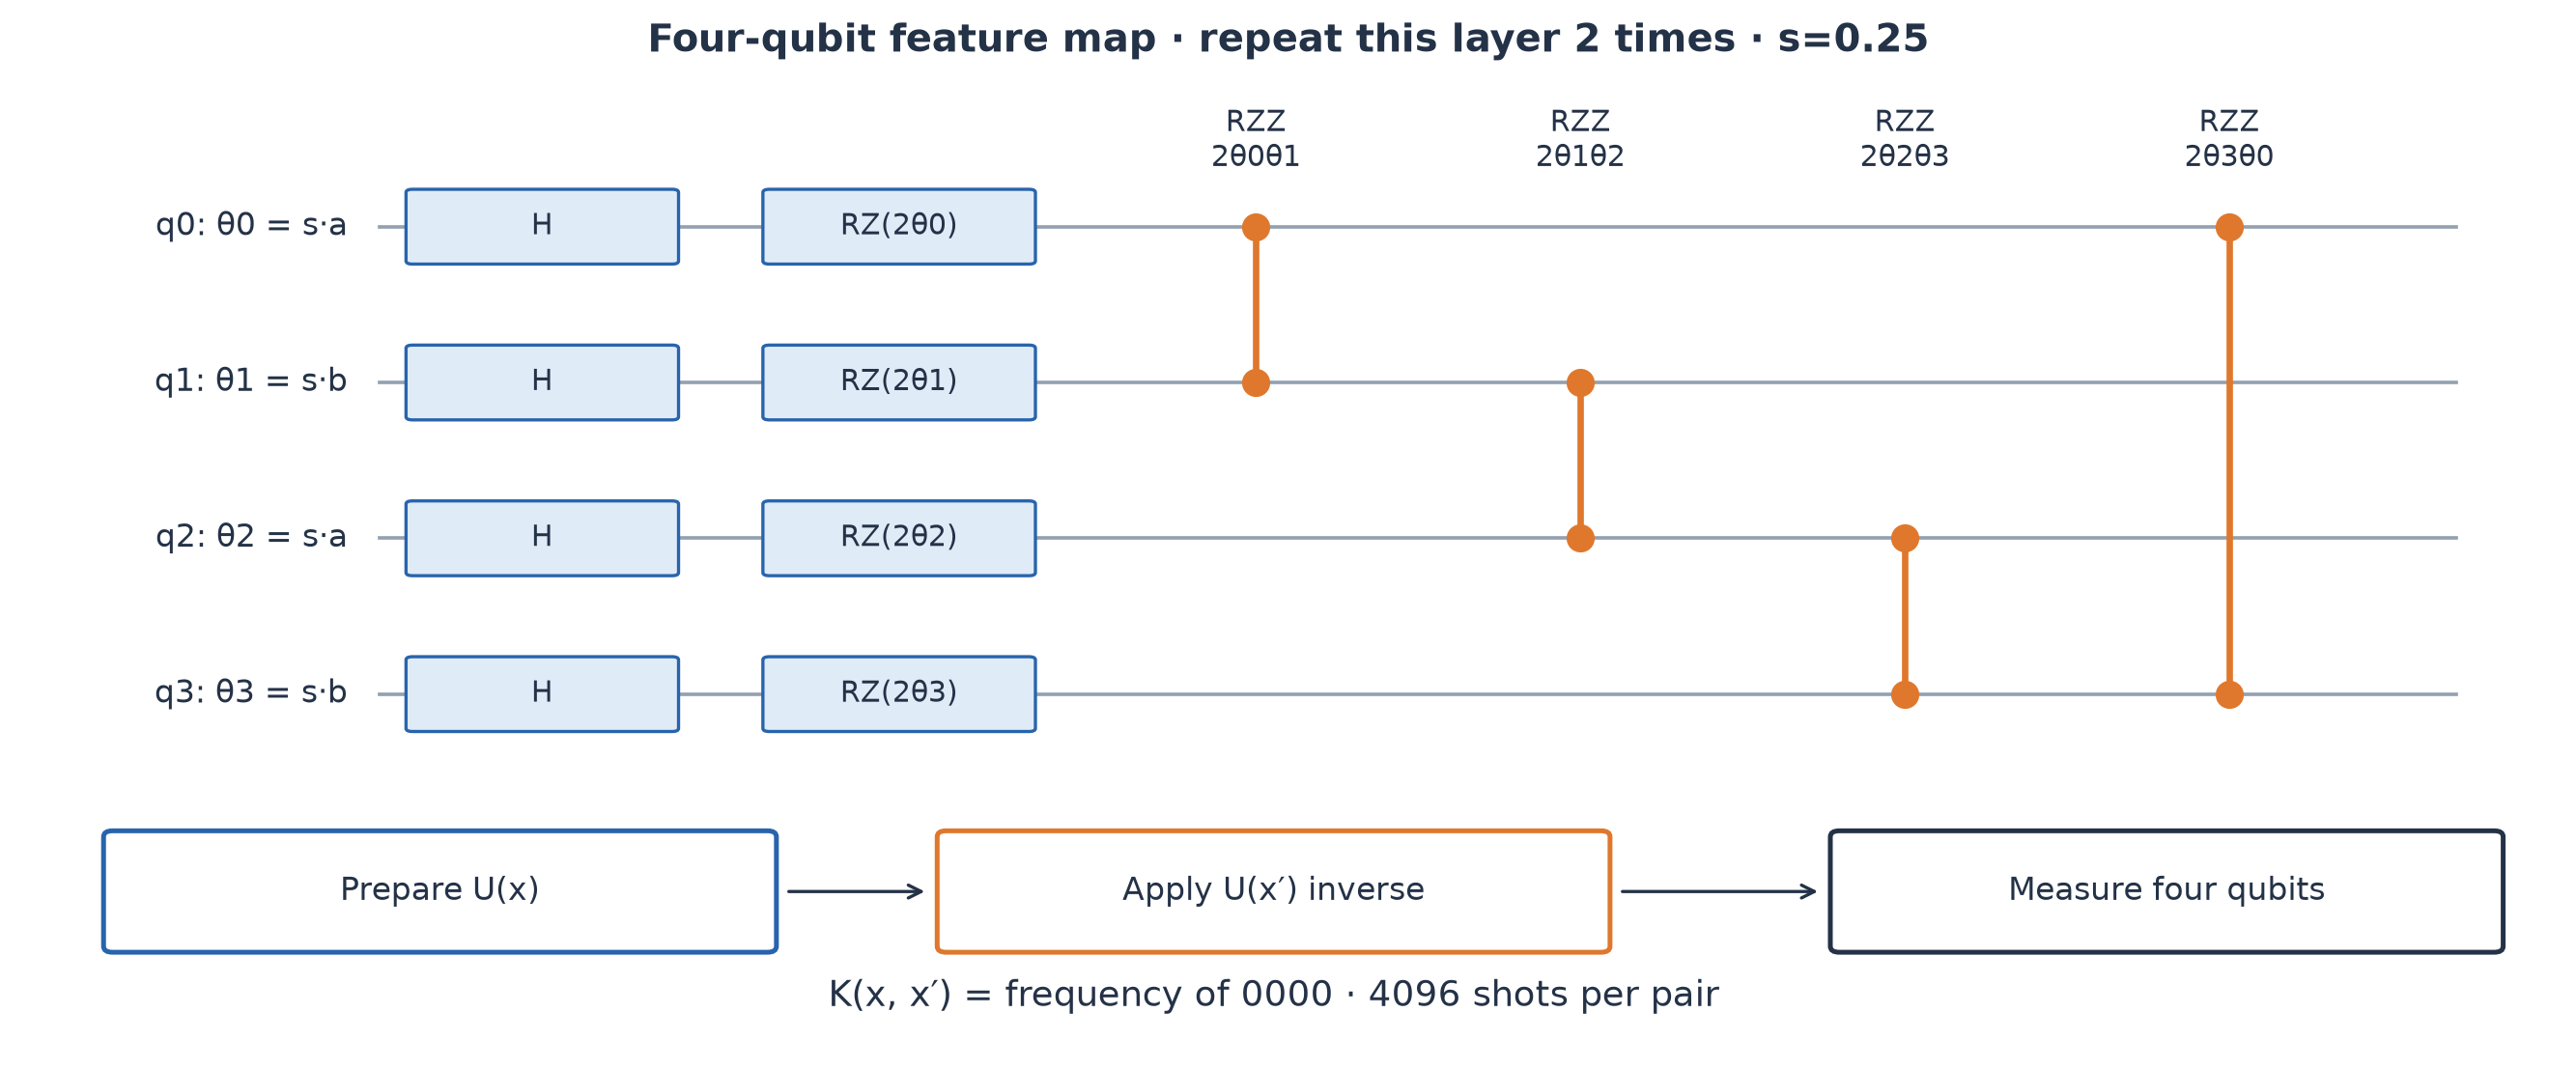

,processor,physical_qubits,initial_layout,depth,cx_count,routing_swaps,evaluated_pairs,total_shots,total_cx_executions
36,A,5,"[0, 1, 2, 3]",89,62,12,4840.0,19824640.0,1.229128e+09
37,B,9,"[0, 1, 4, 3]",63,30,0,4840.0,19824640.0,5.947392e+08


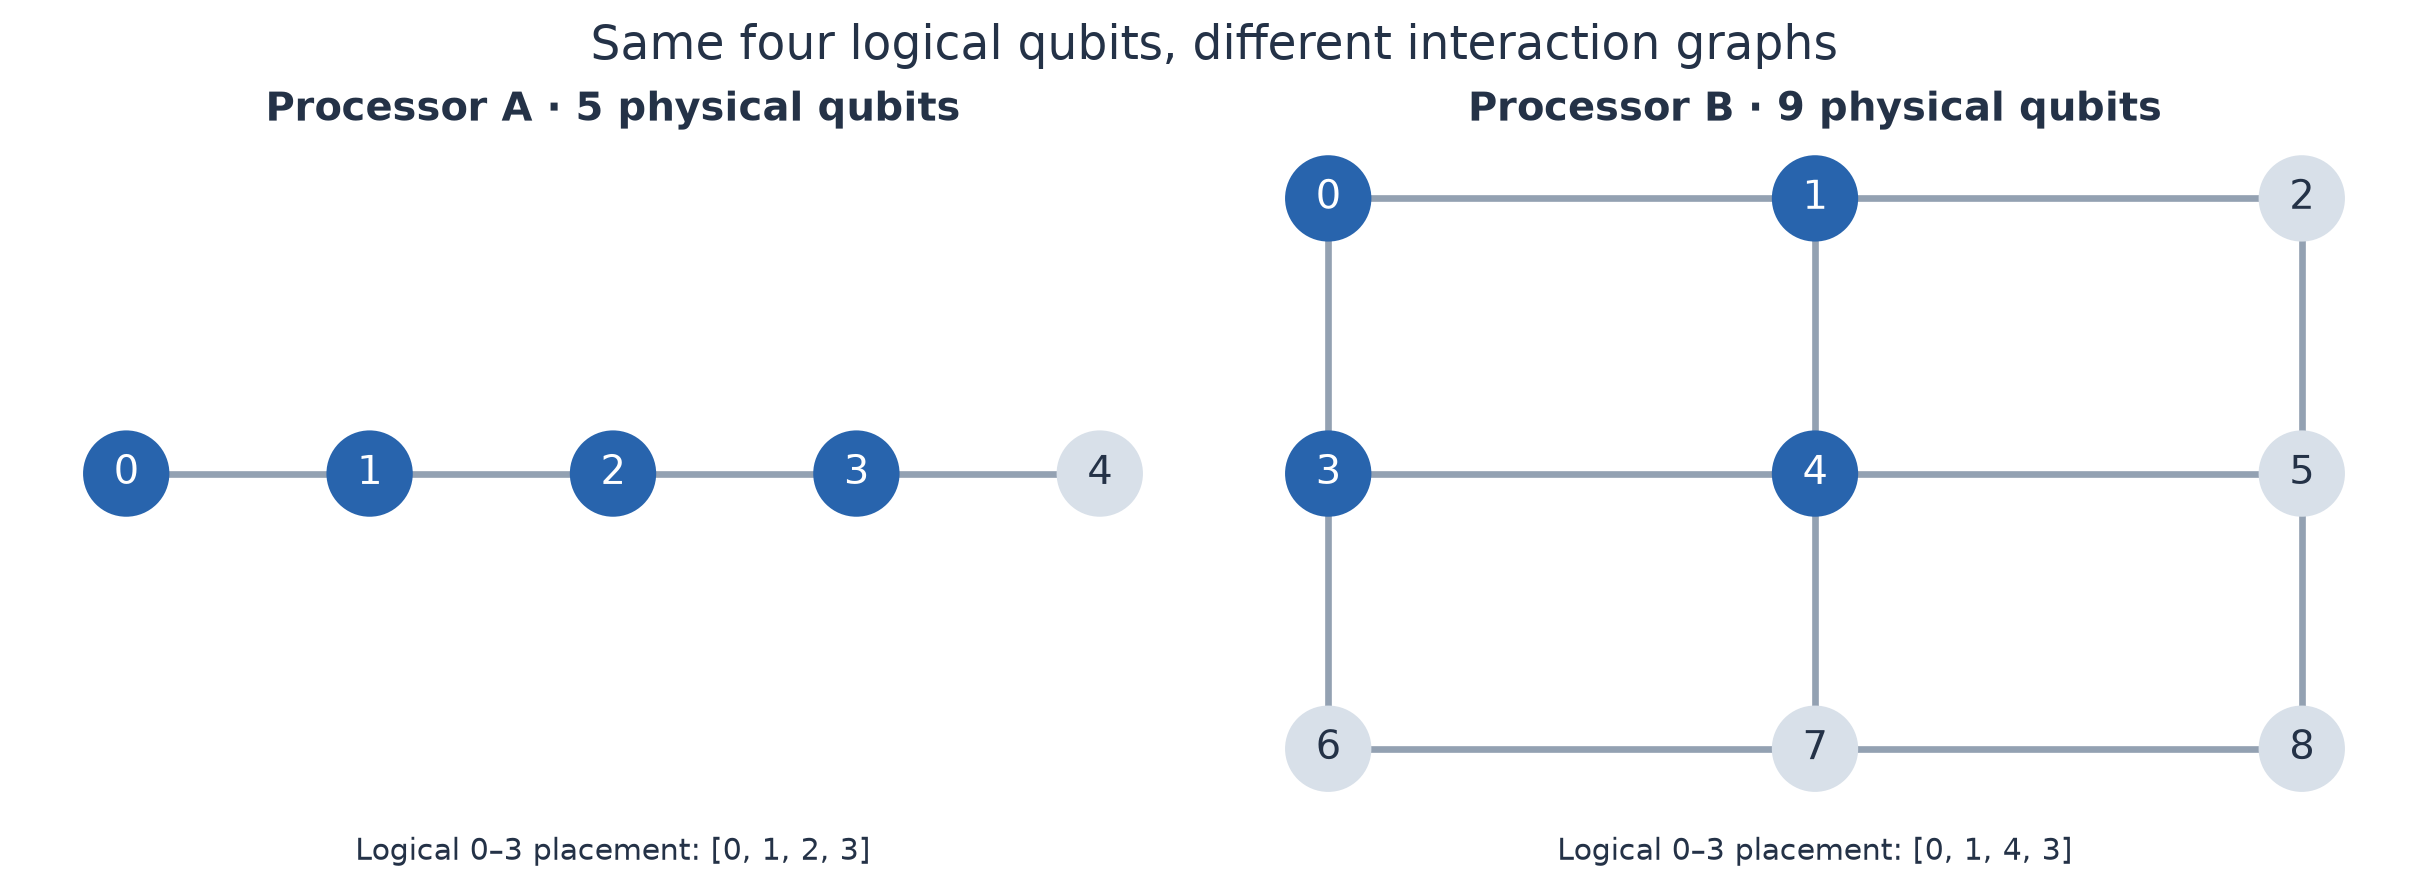

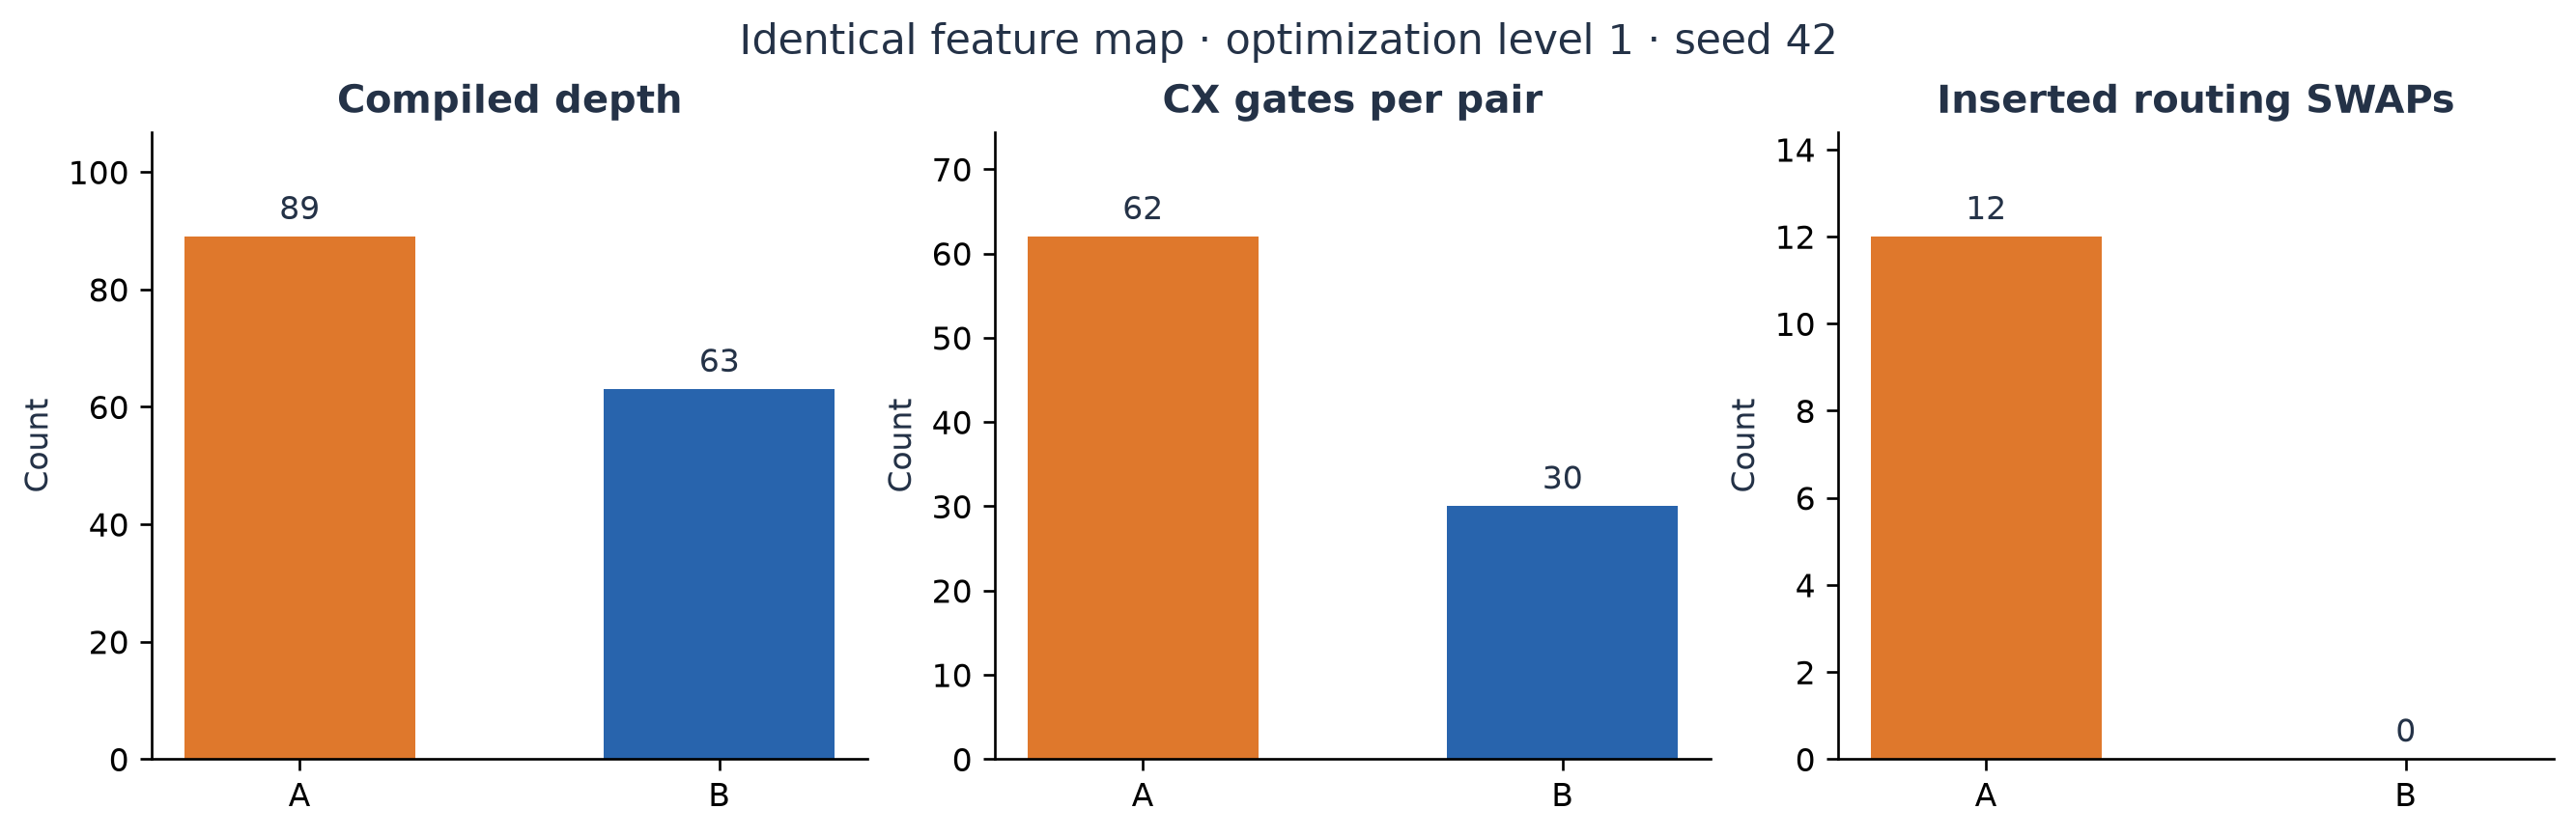

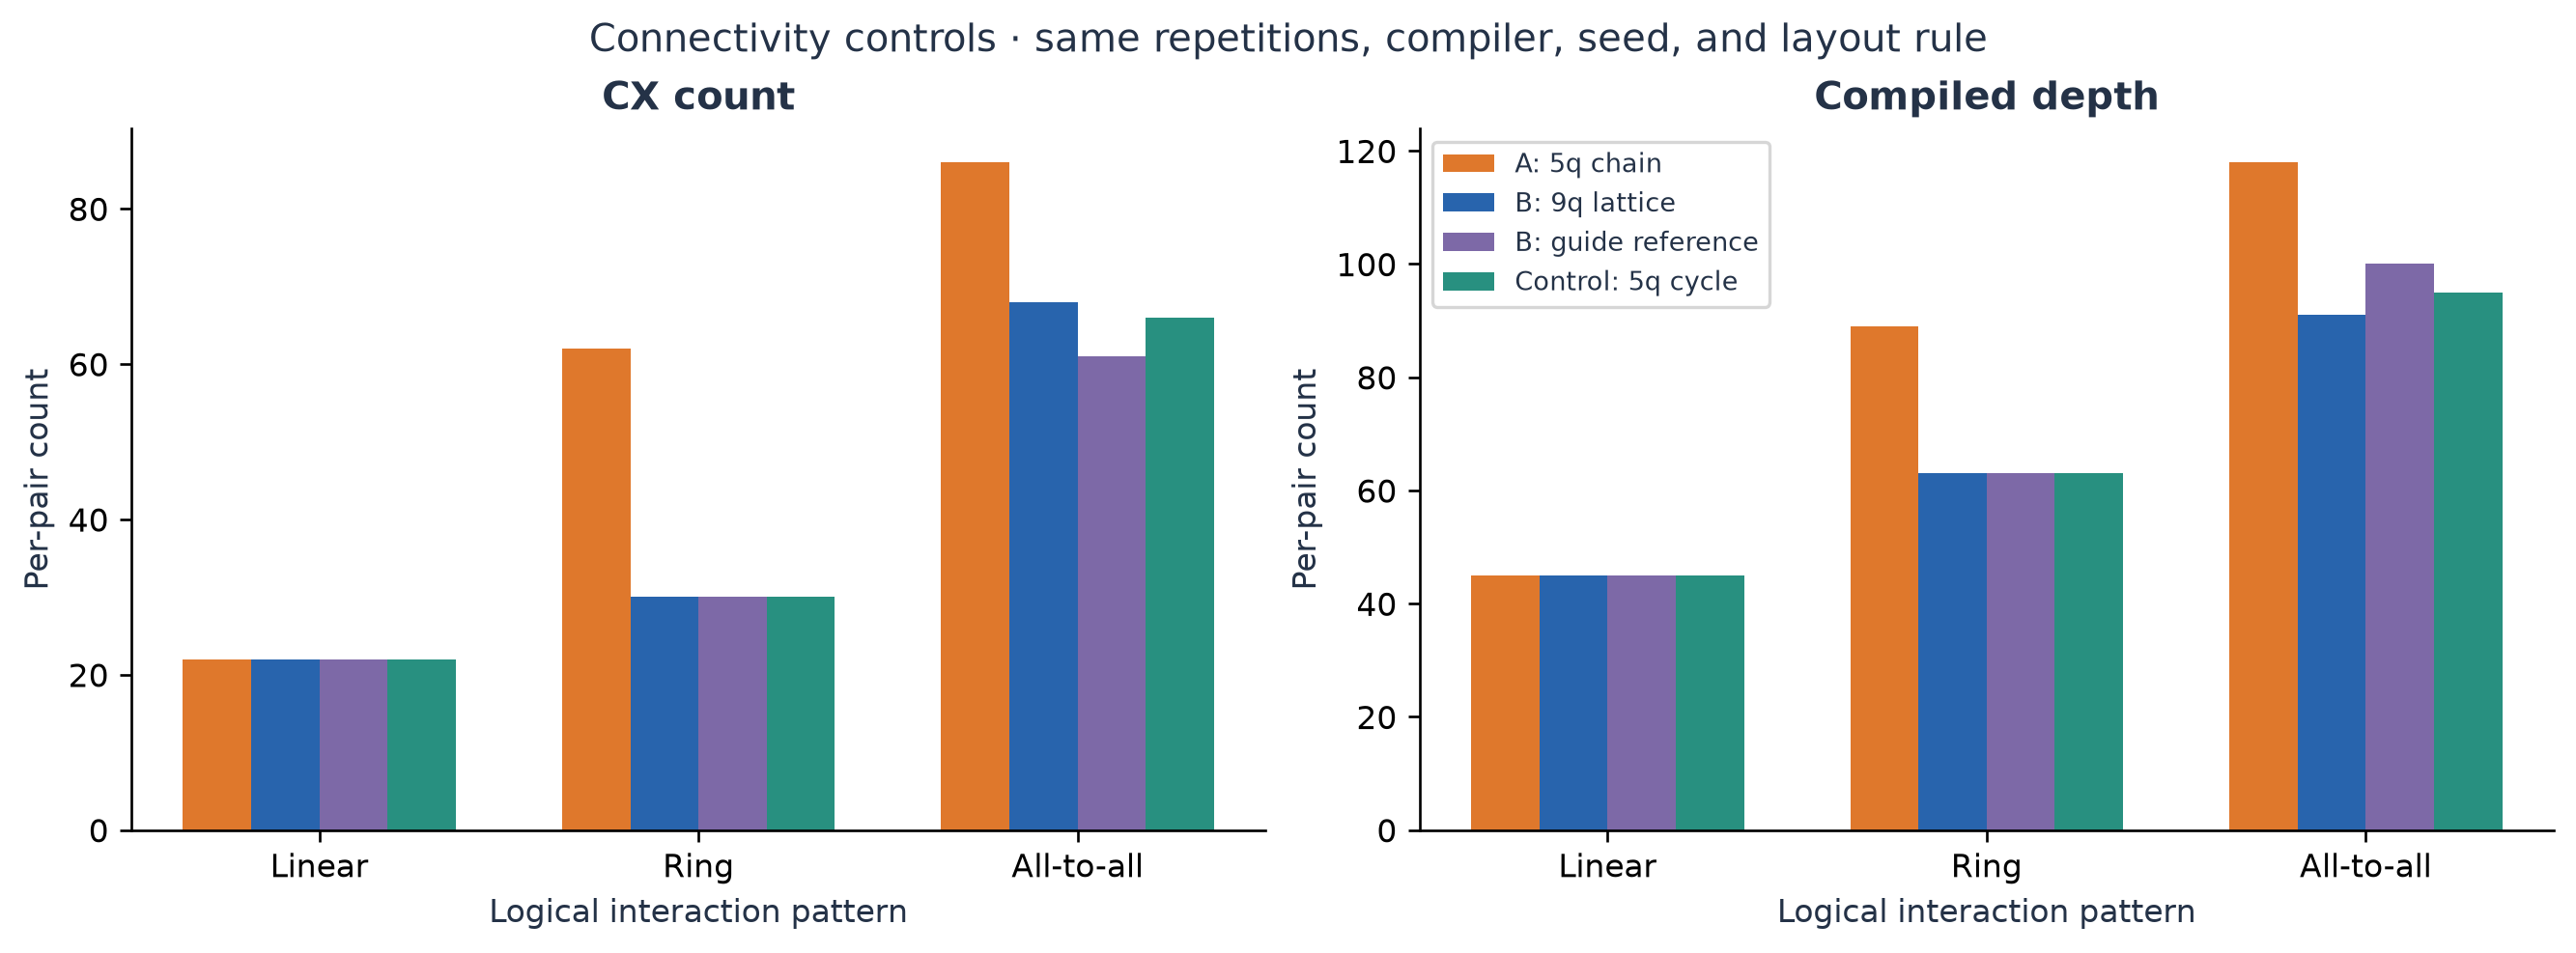

In [4]:
selection = pd.read_csv(ROOT / 'results/tables/quantum_model_selection.csv')
display(selection.head(8))
display(Markdown(f"Selected feature map: **{manifest['feature_map']}**, **C={manifest['C']}**"))
display(Image(filename=str(ROOT / 'results/figures/feature_map.png')))
resources = pd.read_csv(ROOT / 'results/tables/architecture_resources.csv')
display(resources[resources.experiment == 'primary'][[
    'processor', 'physical_qubits', 'initial_layout', 'depth', 'cx_count',
    'routing_swaps', 'evaluated_pairs', 'total_shots', 'total_cx_executions']])
display(Image(filename=str(ROOT / 'results/figures/architectures.png')))
display(Image(filename=str(ROOT / 'results/figures/architecture_cost.png')))
display(Image(filename=str(ROOT / 'results/figures/routing_controls.png')))


## 5. Exact, sampled, noisy, and corrected classification

Linear and RBF SVMs use the same holdout and training-only selection. The exact QSVM establishes algorithmic behavior; ideal binomial samples isolate shot error. Noisy kernels use actual Aer counts.

Raw noisy kernels can be indefinite. The primary noisy classifier retains the positive training eigenspace and extends test similarities through that same eigenspace. Raw matrices are preserved and raw-SVM results are labeled exploratory. Known-channel readout correction is an optional synthetic-model-assisted ablation, not a hardware-calibration result. It cannot undo gate noise.


,model,accuracy,balanced_accuracy,f1,confusion_matrix
0,Classical LINEAR,0.85,0.85,0.823529,"[[10, 0], [3, 7]]"
1,Classical RBF,1.00,1.00,1.000000,"[[10, 0], [0, 10]]"
2,Exact QSVM,1.00,1.00,1.000000,"[[10, 0], [0, 10]]"
3,Ideal shot QSVM,1.00,1.00,1.000000,"[[10, 0], [0, 10]]"
4,A noisy raw,0.95,0.95,0.947368,"[[10, 0], [1, 9]]"
5,A noisy PSD,0.90,0.90,0.888889,"[[10, 0], [2, 8]]"
6,A noise expectation PSD,1.00,1.00,1.000000,"[[10, 0], [0, 10]]"
7,A readout-mitigated PSD,0.90,0.90,0.888889,"[[10, 0], [2, 8]]"
8,B noisy raw,0.95,0.95,0.947368,"[[10, 0], [1, 9]]"
9,B noisy PSD,1.00,1.00,1.000000,"[[10, 0], [0, 10]]"


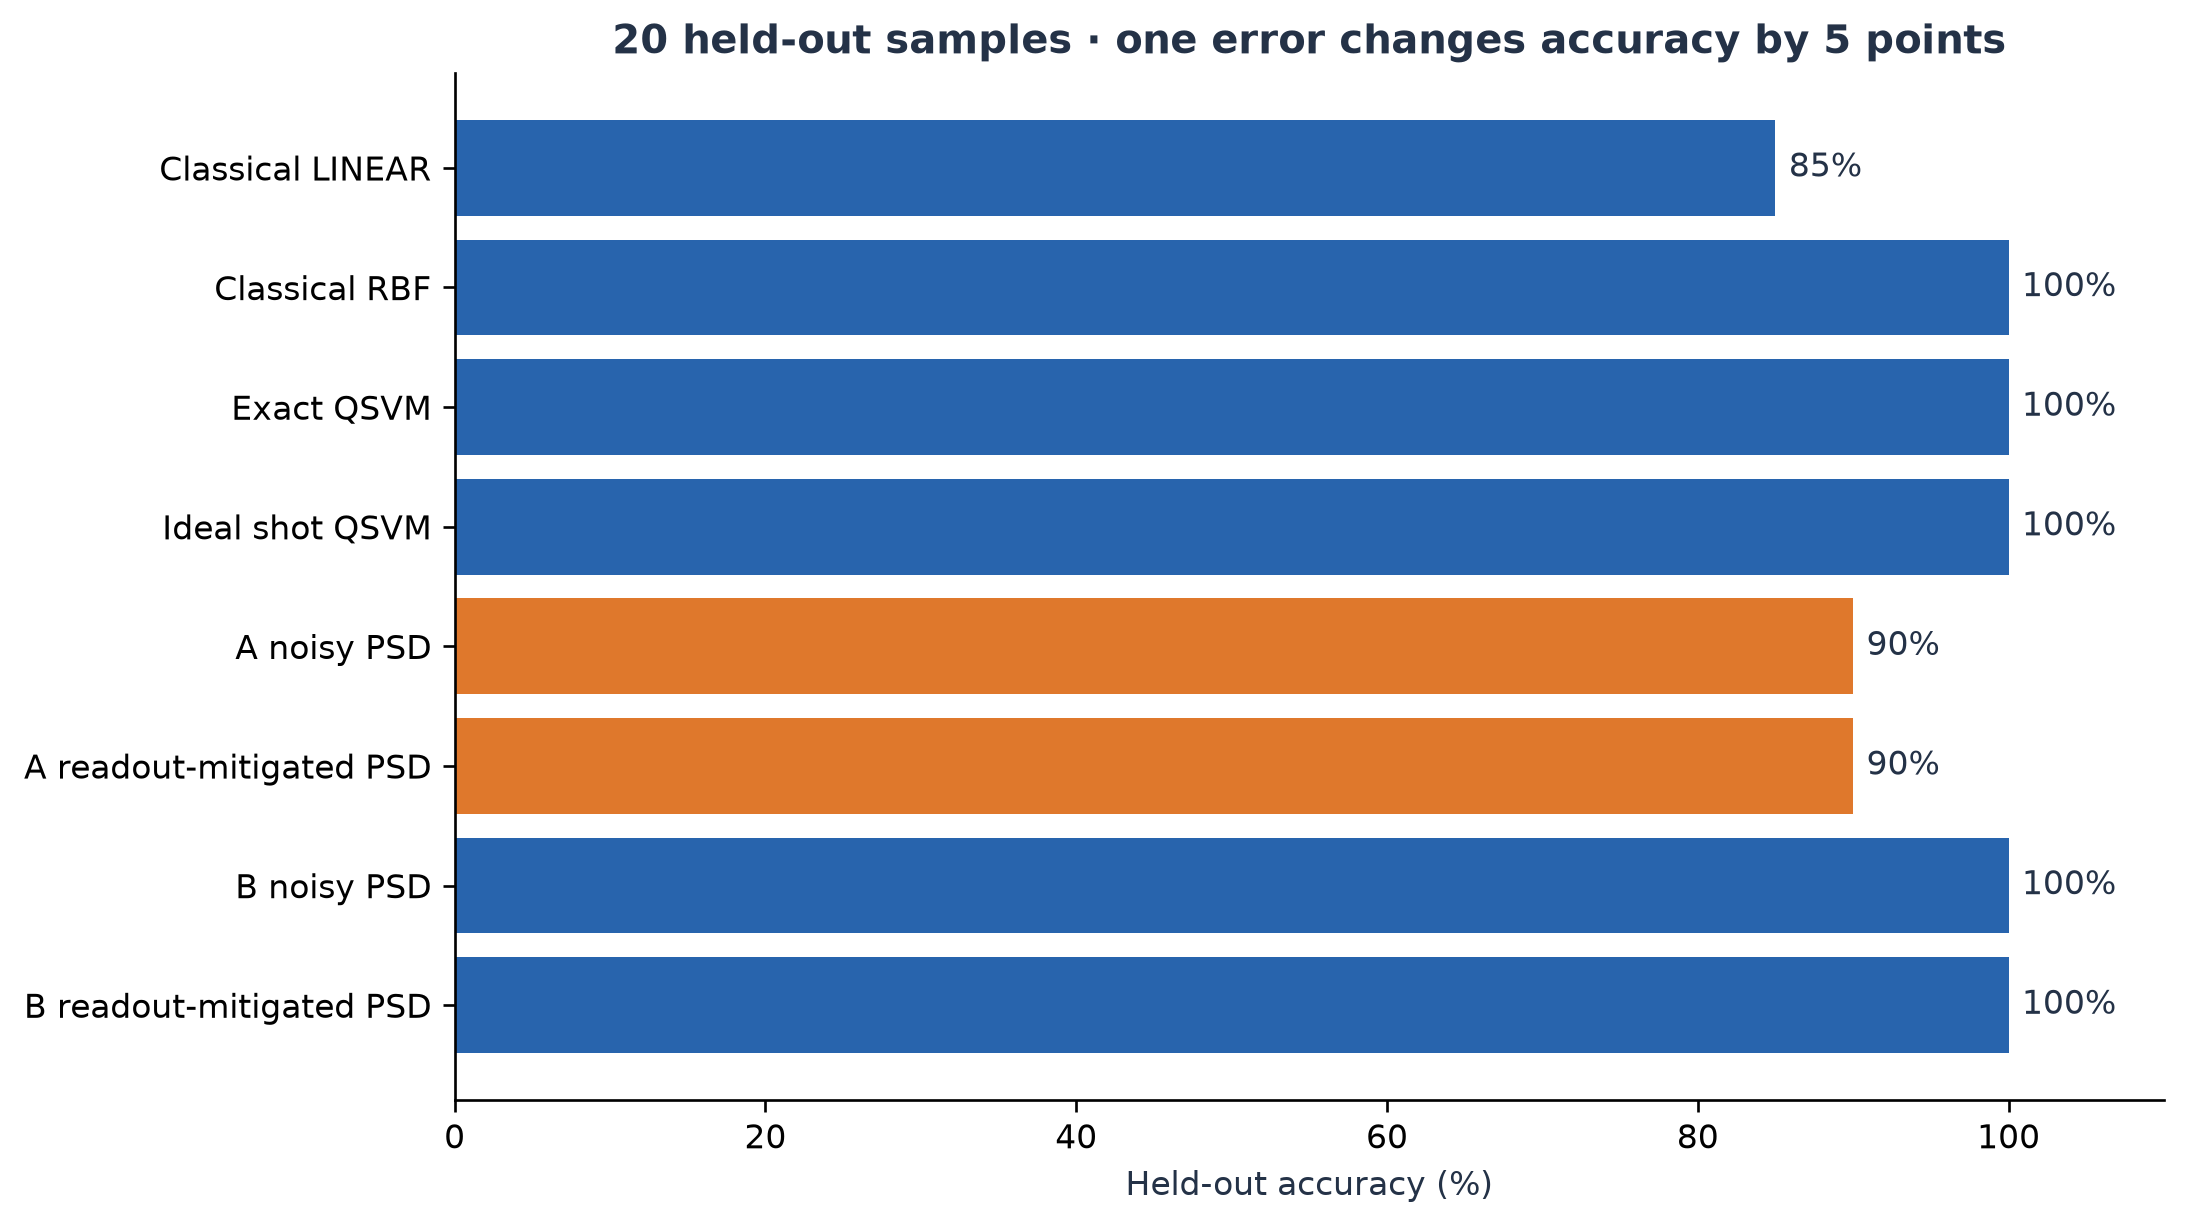

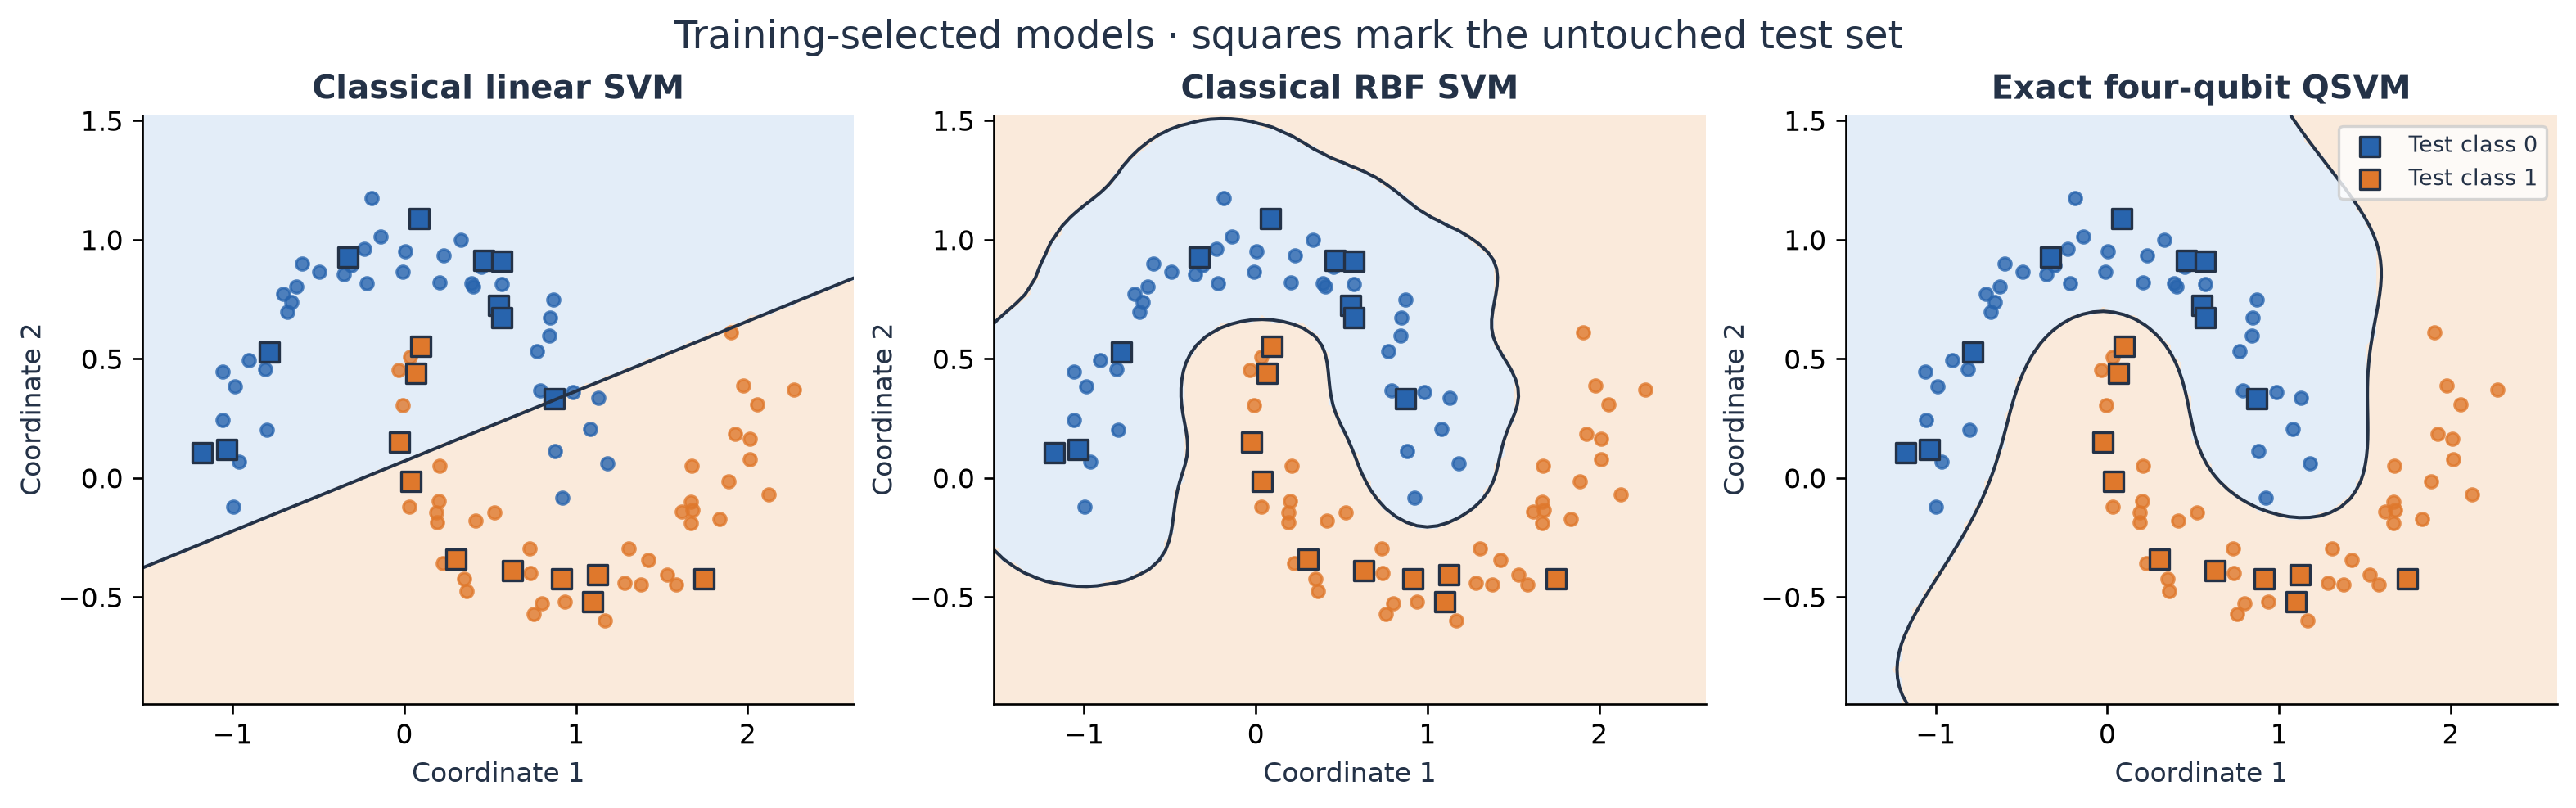

In [5]:
classification = pd.read_csv(ROOT / 'results/tables/classification.csv')
display(classification[['model', 'accuracy', 'balanced_accuracy', 'f1', 'confusion_matrix']])
display(Image(filename=str(ROOT / 'results/figures/classification.png')))
display(Image(filename=str(ROOT / 'results/figures/decision_boundaries.png')))


The boundary plot uses the exact reference only. Its grid is evaluated classically without physical shots; it is not a picture of the noisy classifiers. Every error on this 20-point holdout changes accuracy by five percentage points.

## 6. Kernel distortion, spectrum, and shot budgets

Noise expectations are saved separately from observed shot counts. Kernel errors use the raw matrices, not their repaired versions. The shot study draws 20 Monte Carlo realizations from the known noisy all-zero probabilities for each budget. It measures conditional shot variability, not new hardware acquisitions or uncertainty across datasets. More shots reduce sampling variance while noise bias remains.


,processor,variant,matrix_kind,symmetry_error,diagonal_mean,minimum_eigenvalue,negative_eigenvalues,minimum_entry,maximum_entry,kernel_mae,kernel_rmse,relative_frobenius_error,cross_kernel_rmse,raw_kernel_rmse,raw_cross_kernel_rmse
0,A,noisy raw,raw,0.000000e+00,0.732129,-1.170243e-01,34,0.023193,0.749756,0.135870,0.155762,0.252662,0.158709,0.155762,0.158709
1,A,noisy PSD,corrected,1.110223e-16,0.754179,-7.058513e-15,0,0.024217,0.770875,0.135862,0.155694,0.252551,0.158658,0.155762,0.158709
2,A,noise expectation PSD,corrected,1.110223e-16,0.731355,-3.189957e-15,0,0.022661,0.736613,0.135654,0.155423,0.252112,0.158878,0.155423,0.158878
3,A,readout-mitigated PSD,corrected,1.665335e-16,0.783759,-4.344593e-15,0,0.022538,0.801301,0.121751,0.139406,0.226129,0.141958,0.139489,0.142022
4,B,noisy raw,raw,0.000000e+00,0.823196,-1.137168e-01,34,0.017578,0.834473,0.088894,0.102384,0.166078,0.104409,0.102384,0.104409
5,B,noisy PSD,corrected,1.387779e-16,0.844913,-7.512893e-15,0,0.020792,0.856256,0.088873,0.102284,0.165915,0.104326,0.102384,0.104409
6,B,noise expectation PSD,corrected,2.220446e-16,0.822958,-2.288273e-15,0,0.016412,0.826719,0.088771,0.102018,0.165484,0.104253,0.102018,0.104253
7,B,readout-mitigated PSD,corrected,2.220446e-16,0.878752,-3.228709e-15,0,0.018976,0.890766,0.072706,0.083617,0.135635,0.085215,0.083752,0.085329


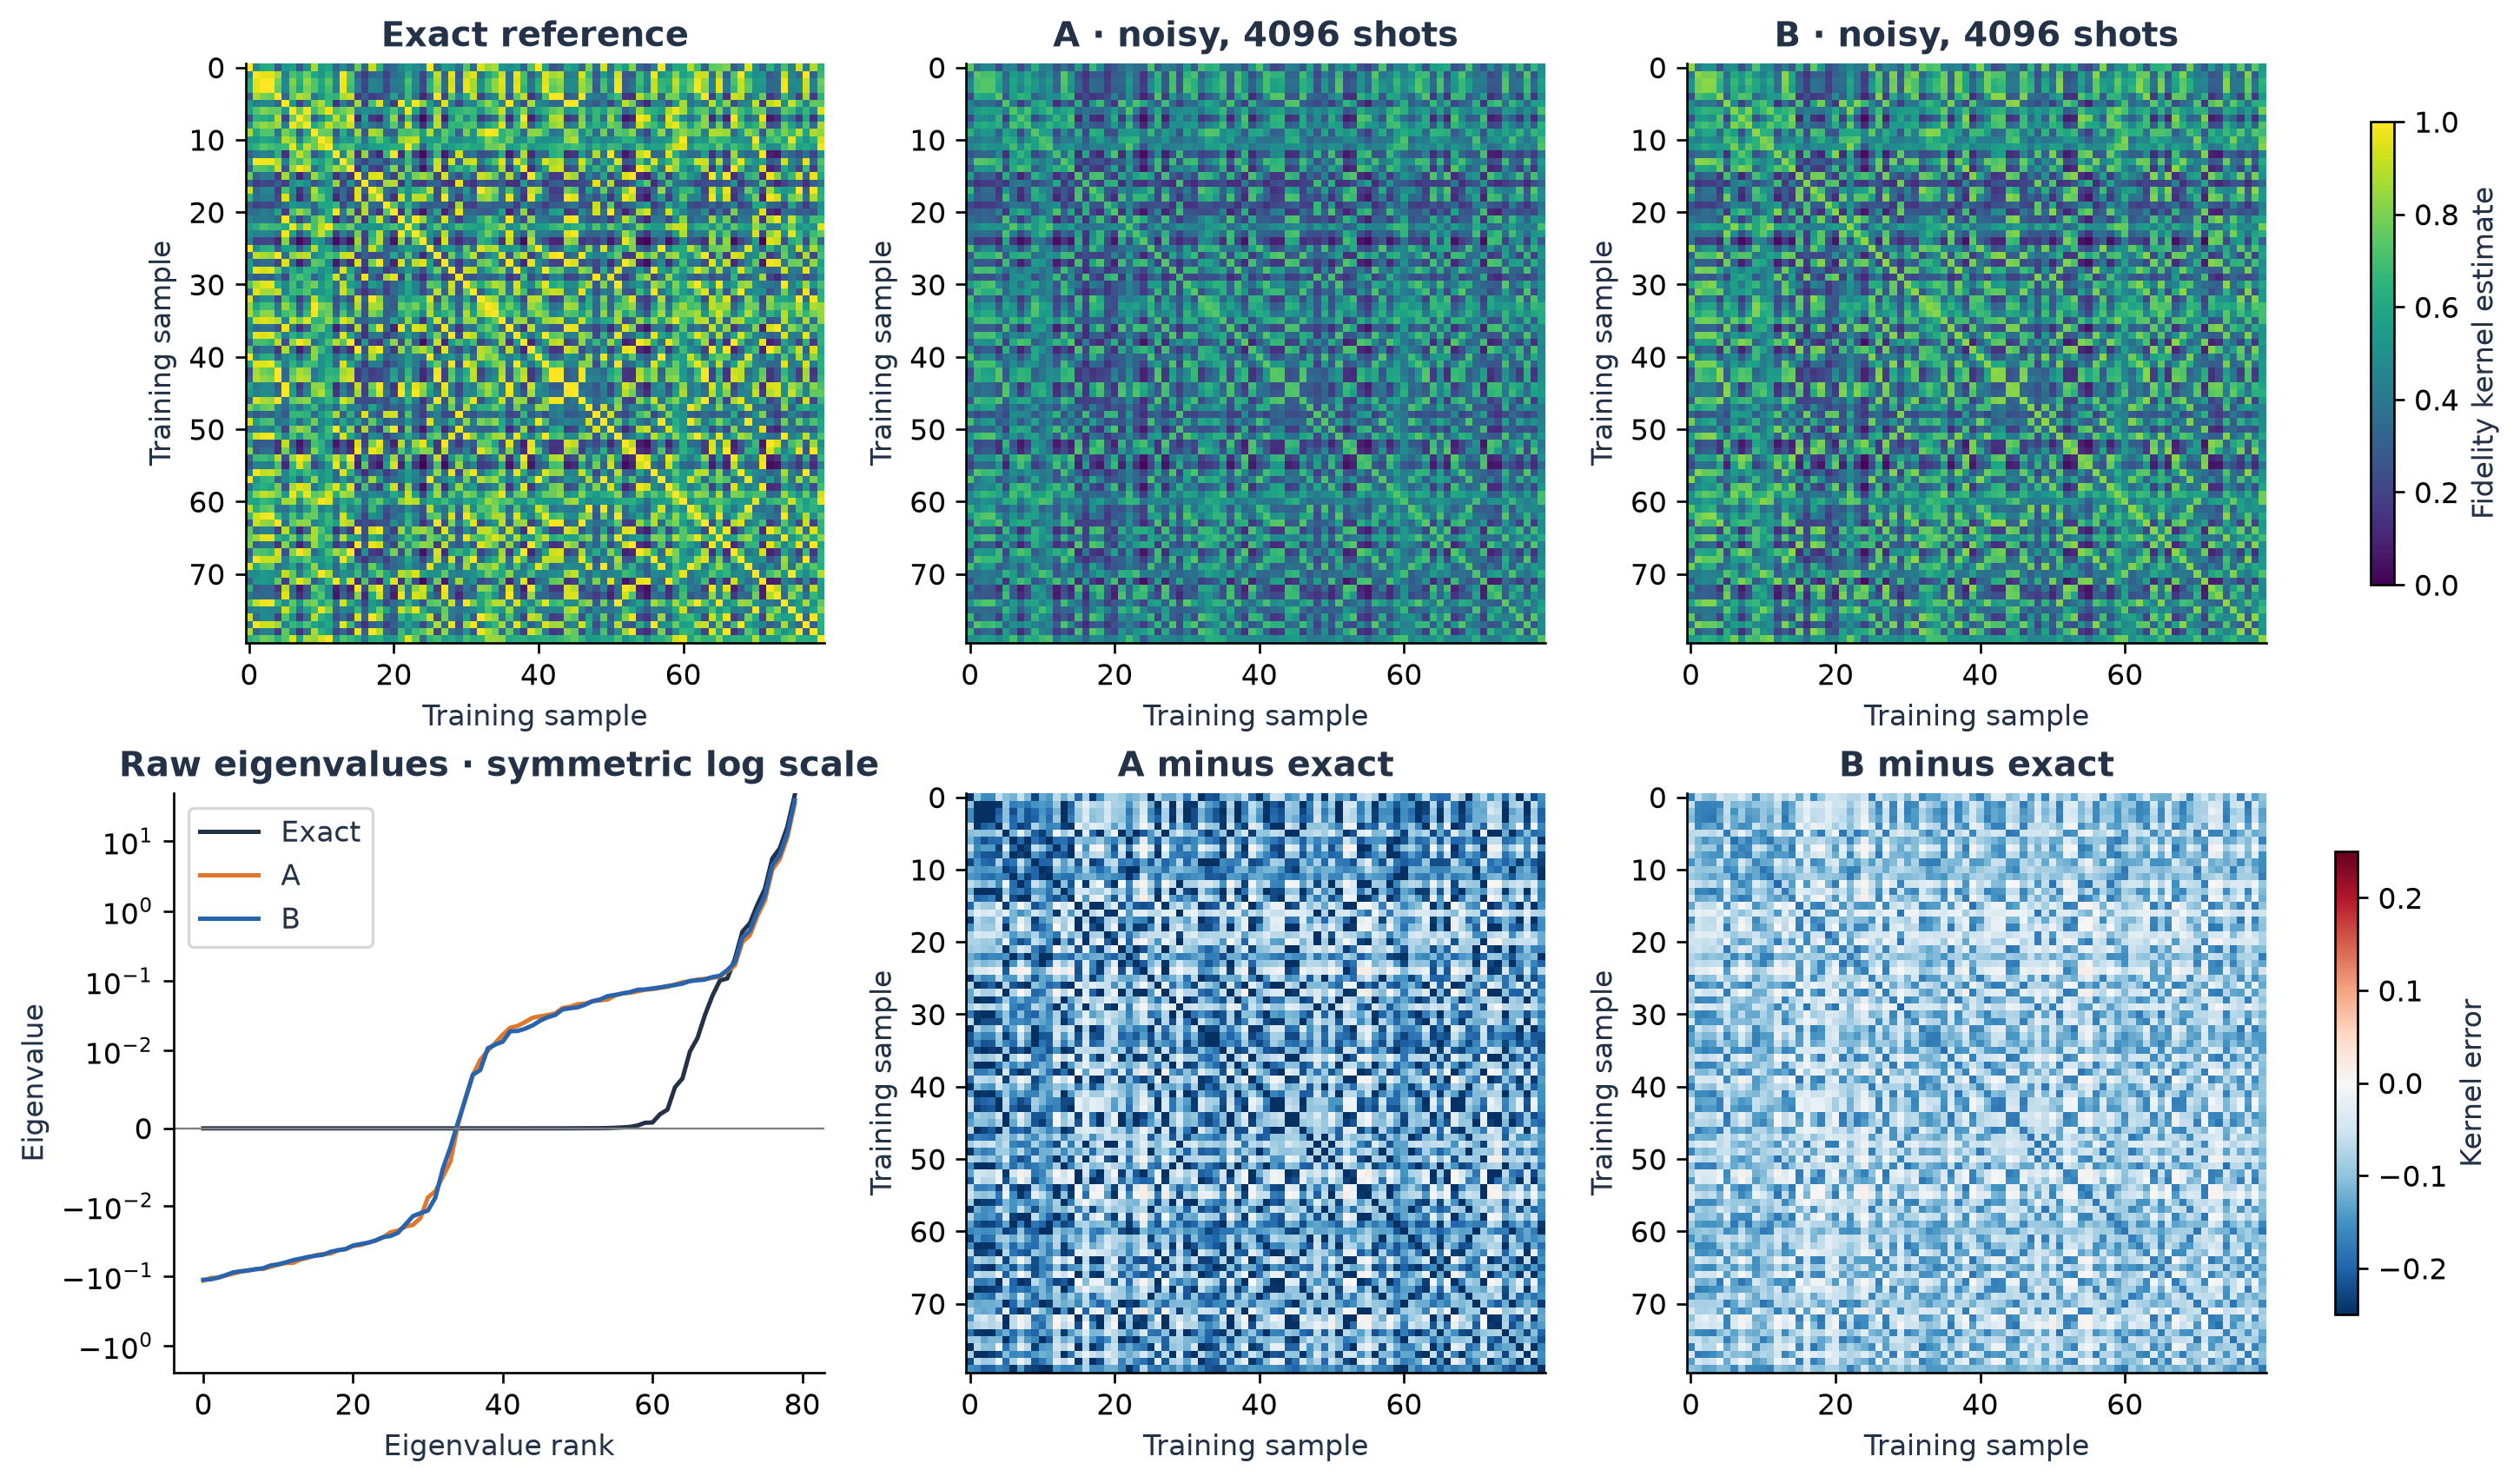

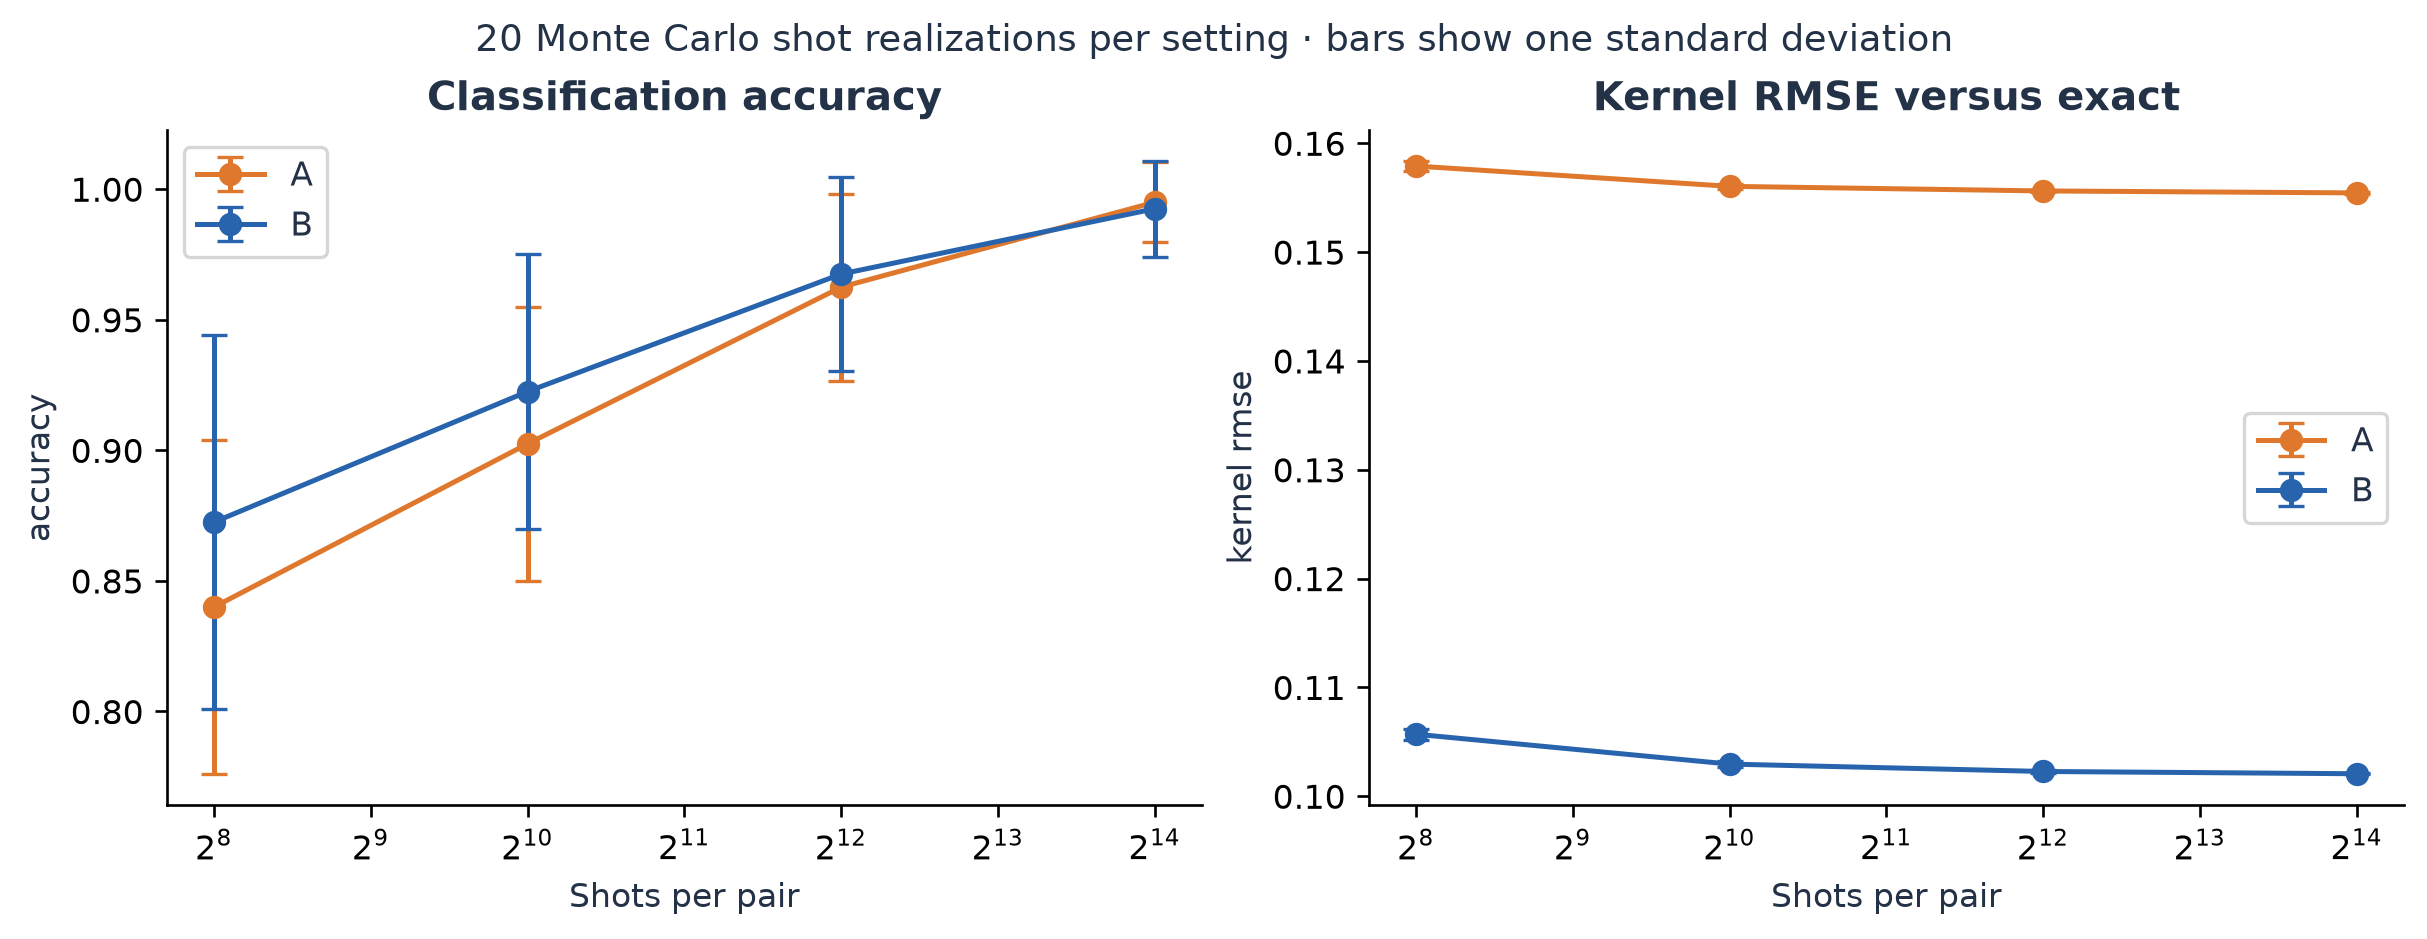

,processor,strategy,feature_map,depth,cx_count,routing_swaps
0,A,sabre,"{'reps': 2, 'scale': 0.25, 'topology': 'linear'}",45,22,0
1,A,basic,"{'reps': 2, 'scale': 0.25, 'topology': 'linear'}",45,22,0
2,A,sabre,"{'reps': 2, 'scale': 0.25, 'topology': 'ring'}",89,62,12
3,A,basic,"{'reps': 2, 'scale': 0.25, 'topology': 'ring'}",91,66,12
4,A,sabre,"{'reps': 2, 'scale': 0.25, 'topology': 'full'}",118,86,14
5,A,basic,"{'reps': 2, 'scale': 0.25, 'topology': 'full'}",147,122,26
9,B,sabre,"{'reps': 2, 'scale': 0.25, 'topology': 'linear'}",45,22,0
10,B,basic,"{'reps': 2, 'scale': 0.25, 'topology': 'linear'}",45,22,0
11,B,sabre,"{'reps': 2, 'scale': 0.25, 'topology': 'ring'}",63,30,0
12,B,basic,"{'reps': 2, 'scale': 0.25, 'topology': 'ring'}",63,30,0


In [6]:
display(pd.read_csv(ROOT / 'results/tables/kernel_diagnostics.csv'))
display(Image(filename=str(ROOT / 'results/figures/kernel_comparison.png')))
display(Image(filename=str(ROOT / 'results/figures/shot_sensitivity.png')))
display(resources[resources.experiment == 'routing_control'][[
    'processor', 'strategy', 'feature_map', 'depth', 'cx_count', 'routing_swaps']])


## 7. Architecture exploration and exact optimization

The topology grid compares three A and three B graphs under linear, ring, and full K4 interactions with two routing methods. Tree processors receive actual 4,096-shot kernel measurements. Fused-SABRE isolates central diagonal fusion; native parity synthesis additionally eliminates routing. These transformations preserve the complete ideal unitary. All compiler comparisons freeze the original feature map and SVM C.

The encoding and cost/quality controls use training folds only. Ten predeclared split seeds independently repeat model selection for exact QSVM and classical baselines. Repeated splits reuse the same prescribed data and do not estimate noisy hardware performance.


,processor,compiler,depth,cx_count,routing_swaps,kernel_rmse,accuracy,aer_seconds
0,A,baseline,89,62,12,0.155762,0.9,33.909574
1,B,baseline,63,30,0,0.102384,1.0,32.204066
2,A,fused_sabre,74,50,10,0.134697,0.9,43.554527
3,B,fused_sabre,52,24,0,0.089490,1.0,39.926708
4,A,fused_parity,52,30,0,0.104198,1.0,43.349145
5,B,fused_parity,52,24,0,0.089490,1.0,33.948782
6,A_tree,baseline,93,48,6,0.133253,0.9,42.241471
7,B_tree,baseline,90,63,13,0.157301,0.9,47.366700


,processor,compiler,mean,std,min,max
0,A,baseline,0.9625,0.035818,0.90,1.0
1,A,fused_parity,0.9625,0.045523,0.85,1.0
2,A,fused_sabre,0.9700,0.029912,0.90,1.0
3,A_tree,baseline,0.9625,0.045523,0.85,1.0
4,B,baseline,0.9675,0.037258,0.90,1.0
5,B,fused_parity,0.9650,0.032847,0.90,1.0
6,B,fused_sabre,0.9650,0.032847,0.90,1.0
7,B_tree,baseline,0.9575,0.037258,0.90,1.0


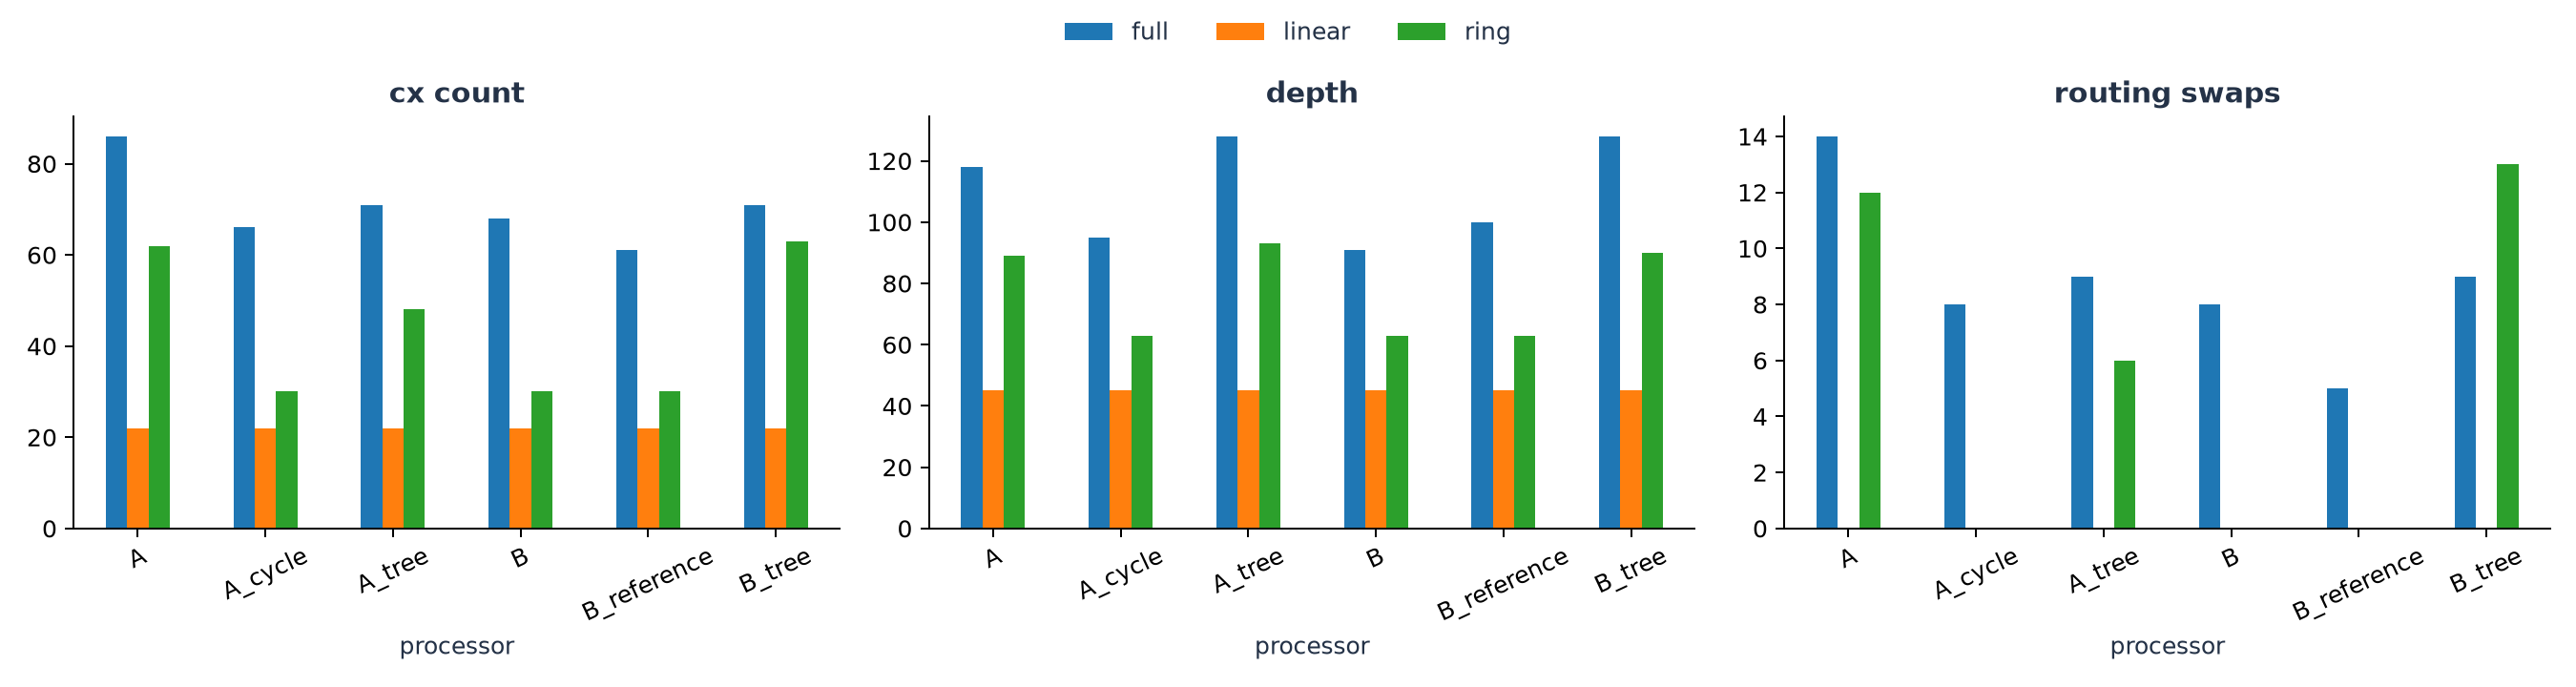

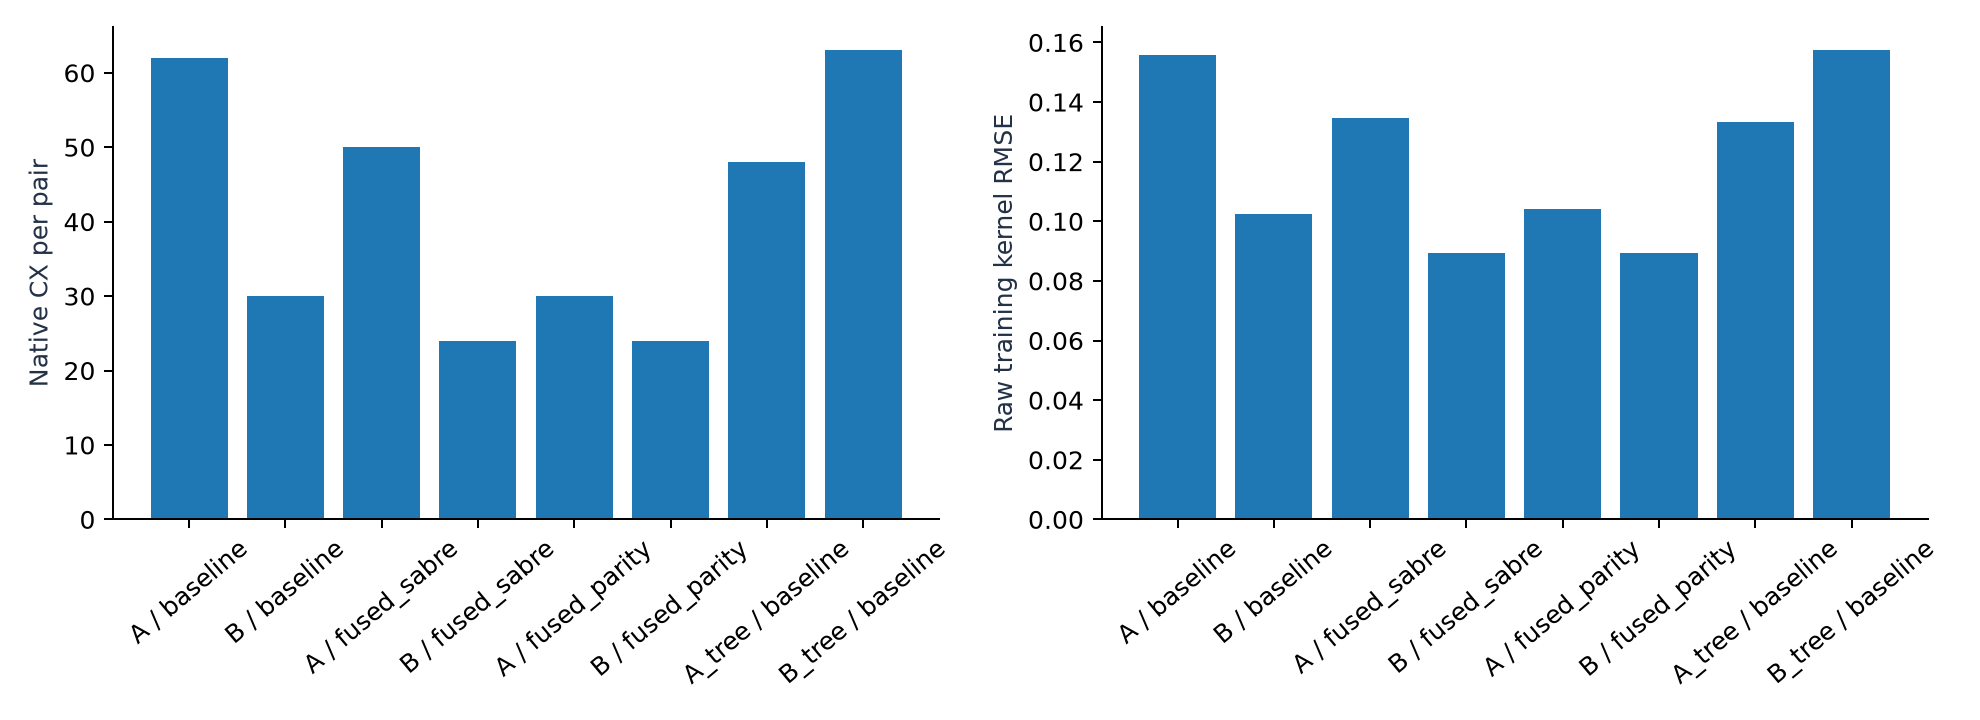

,encoding,reps,scale,C,cv_mean,cv_std,fold_scores
0,repeated_coordinates,2,0.25,0.1,0.8750,0.044194,"[0.9375, 0.875, 0.875, 0.875, 0.8125]"
1,repeated_coordinates,2,0.25,1.0,0.9000,0.055902,"[0.9375, 0.9375, 0.875, 0.9375, 0.8125]"
2,repeated_coordinates,2,0.25,10.0,0.9375,0.062500,"[1.0, 1.0, 0.875, 0.9375, 0.875]"
3,repeated_coordinates,2,0.25,100.0,1.0000,0.000000,"[1.0, 1.0, 1.0, 1.0, 1.0]"
4,mean_difference_coordinates,2,0.25,0.1,0.8750,0.044194,"[0.9375, 0.875, 0.875, 0.875, 0.8125]"
5,mean_difference_coordinates,2,0.25,1.0,0.9000,0.055902,"[0.9375, 0.9375, 0.875, 0.9375, 0.8125]"
6,mean_difference_coordinates,2,0.25,10.0,0.9375,0.062500,"[1.0, 1.0, 0.875, 0.9375, 0.875]"
7,mean_difference_coordinates,2,0.25,100.0,0.9625,0.034233,"[1.0, 1.0, 0.9375, 0.9375, 0.9375]"


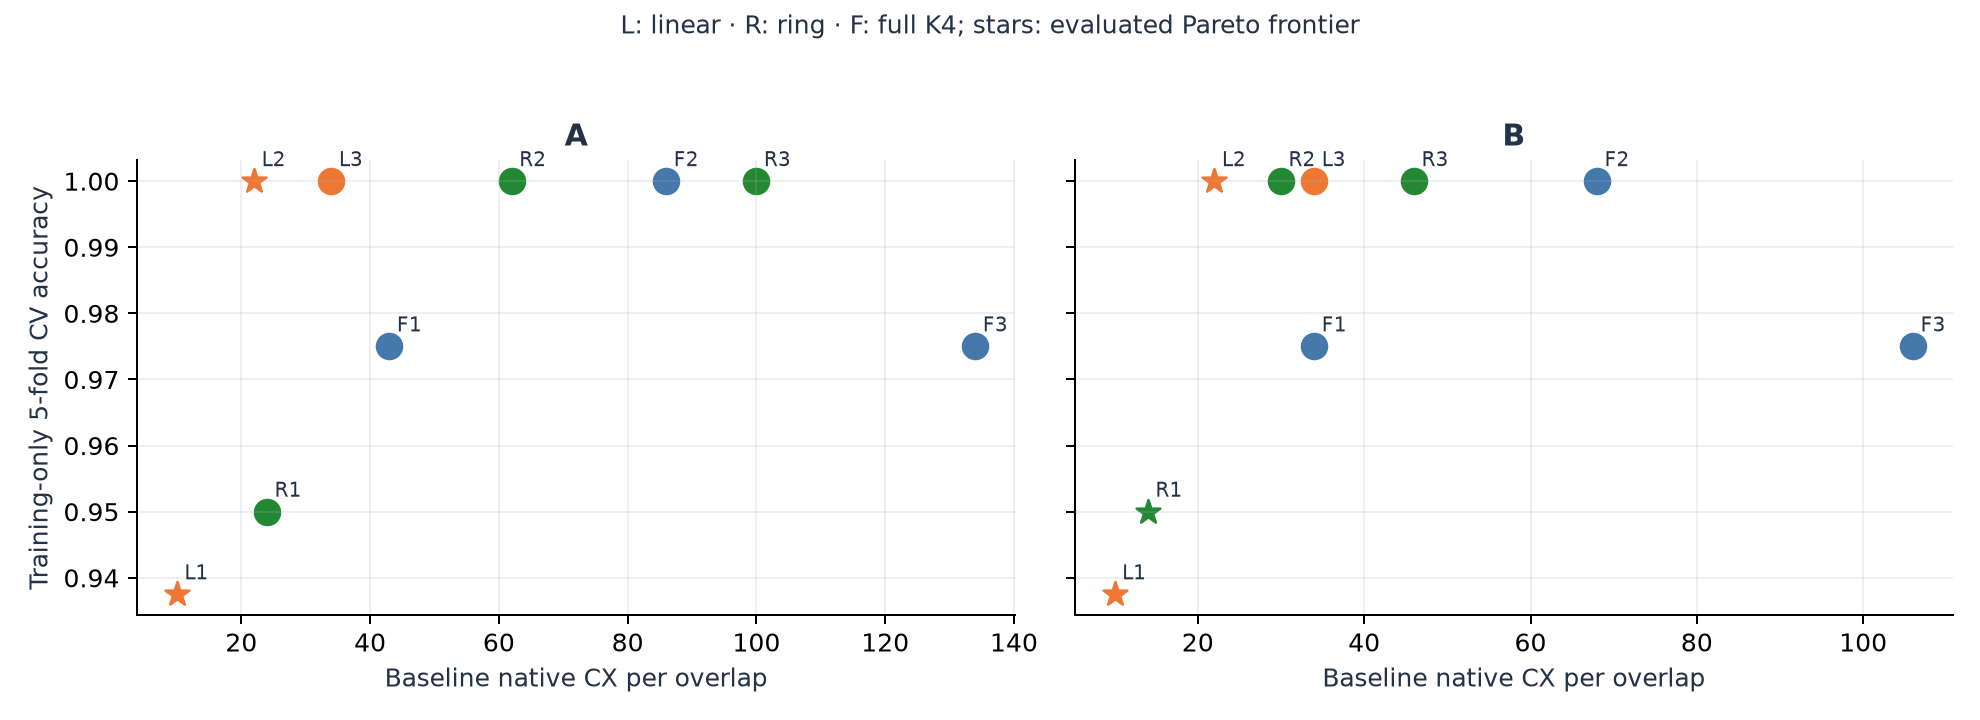

,processor,reps,scale,topology,C,cv_mean,depth,cx_count,routing_swaps,accuracy,kernel_rmse_vs_own_exact,compiled_error,aer_seconds,cache_hit_batches
0,A,2,0.25,linear,100.0,1.0,45,22,0,1.0,0.089084,4.996004e-15,35.898608,38
1,B,2,0.25,linear,100.0,1.0,45,22,0,1.0,0.089084,4.996004e-15,36.672451,38


,processor,mean,std,min,max
0,A,0.92,0.044129,0.85,1.0
1,B,0.92,0.044129,0.85,1.0


,mean,std,min,max
model,,,,
Classical LINEAR,0.850,0.062361,0.75,0.95
Classical RBF,0.995,0.015811,0.95,1.00
Exact QSVM,1.000,0.000000,1.00,1.00


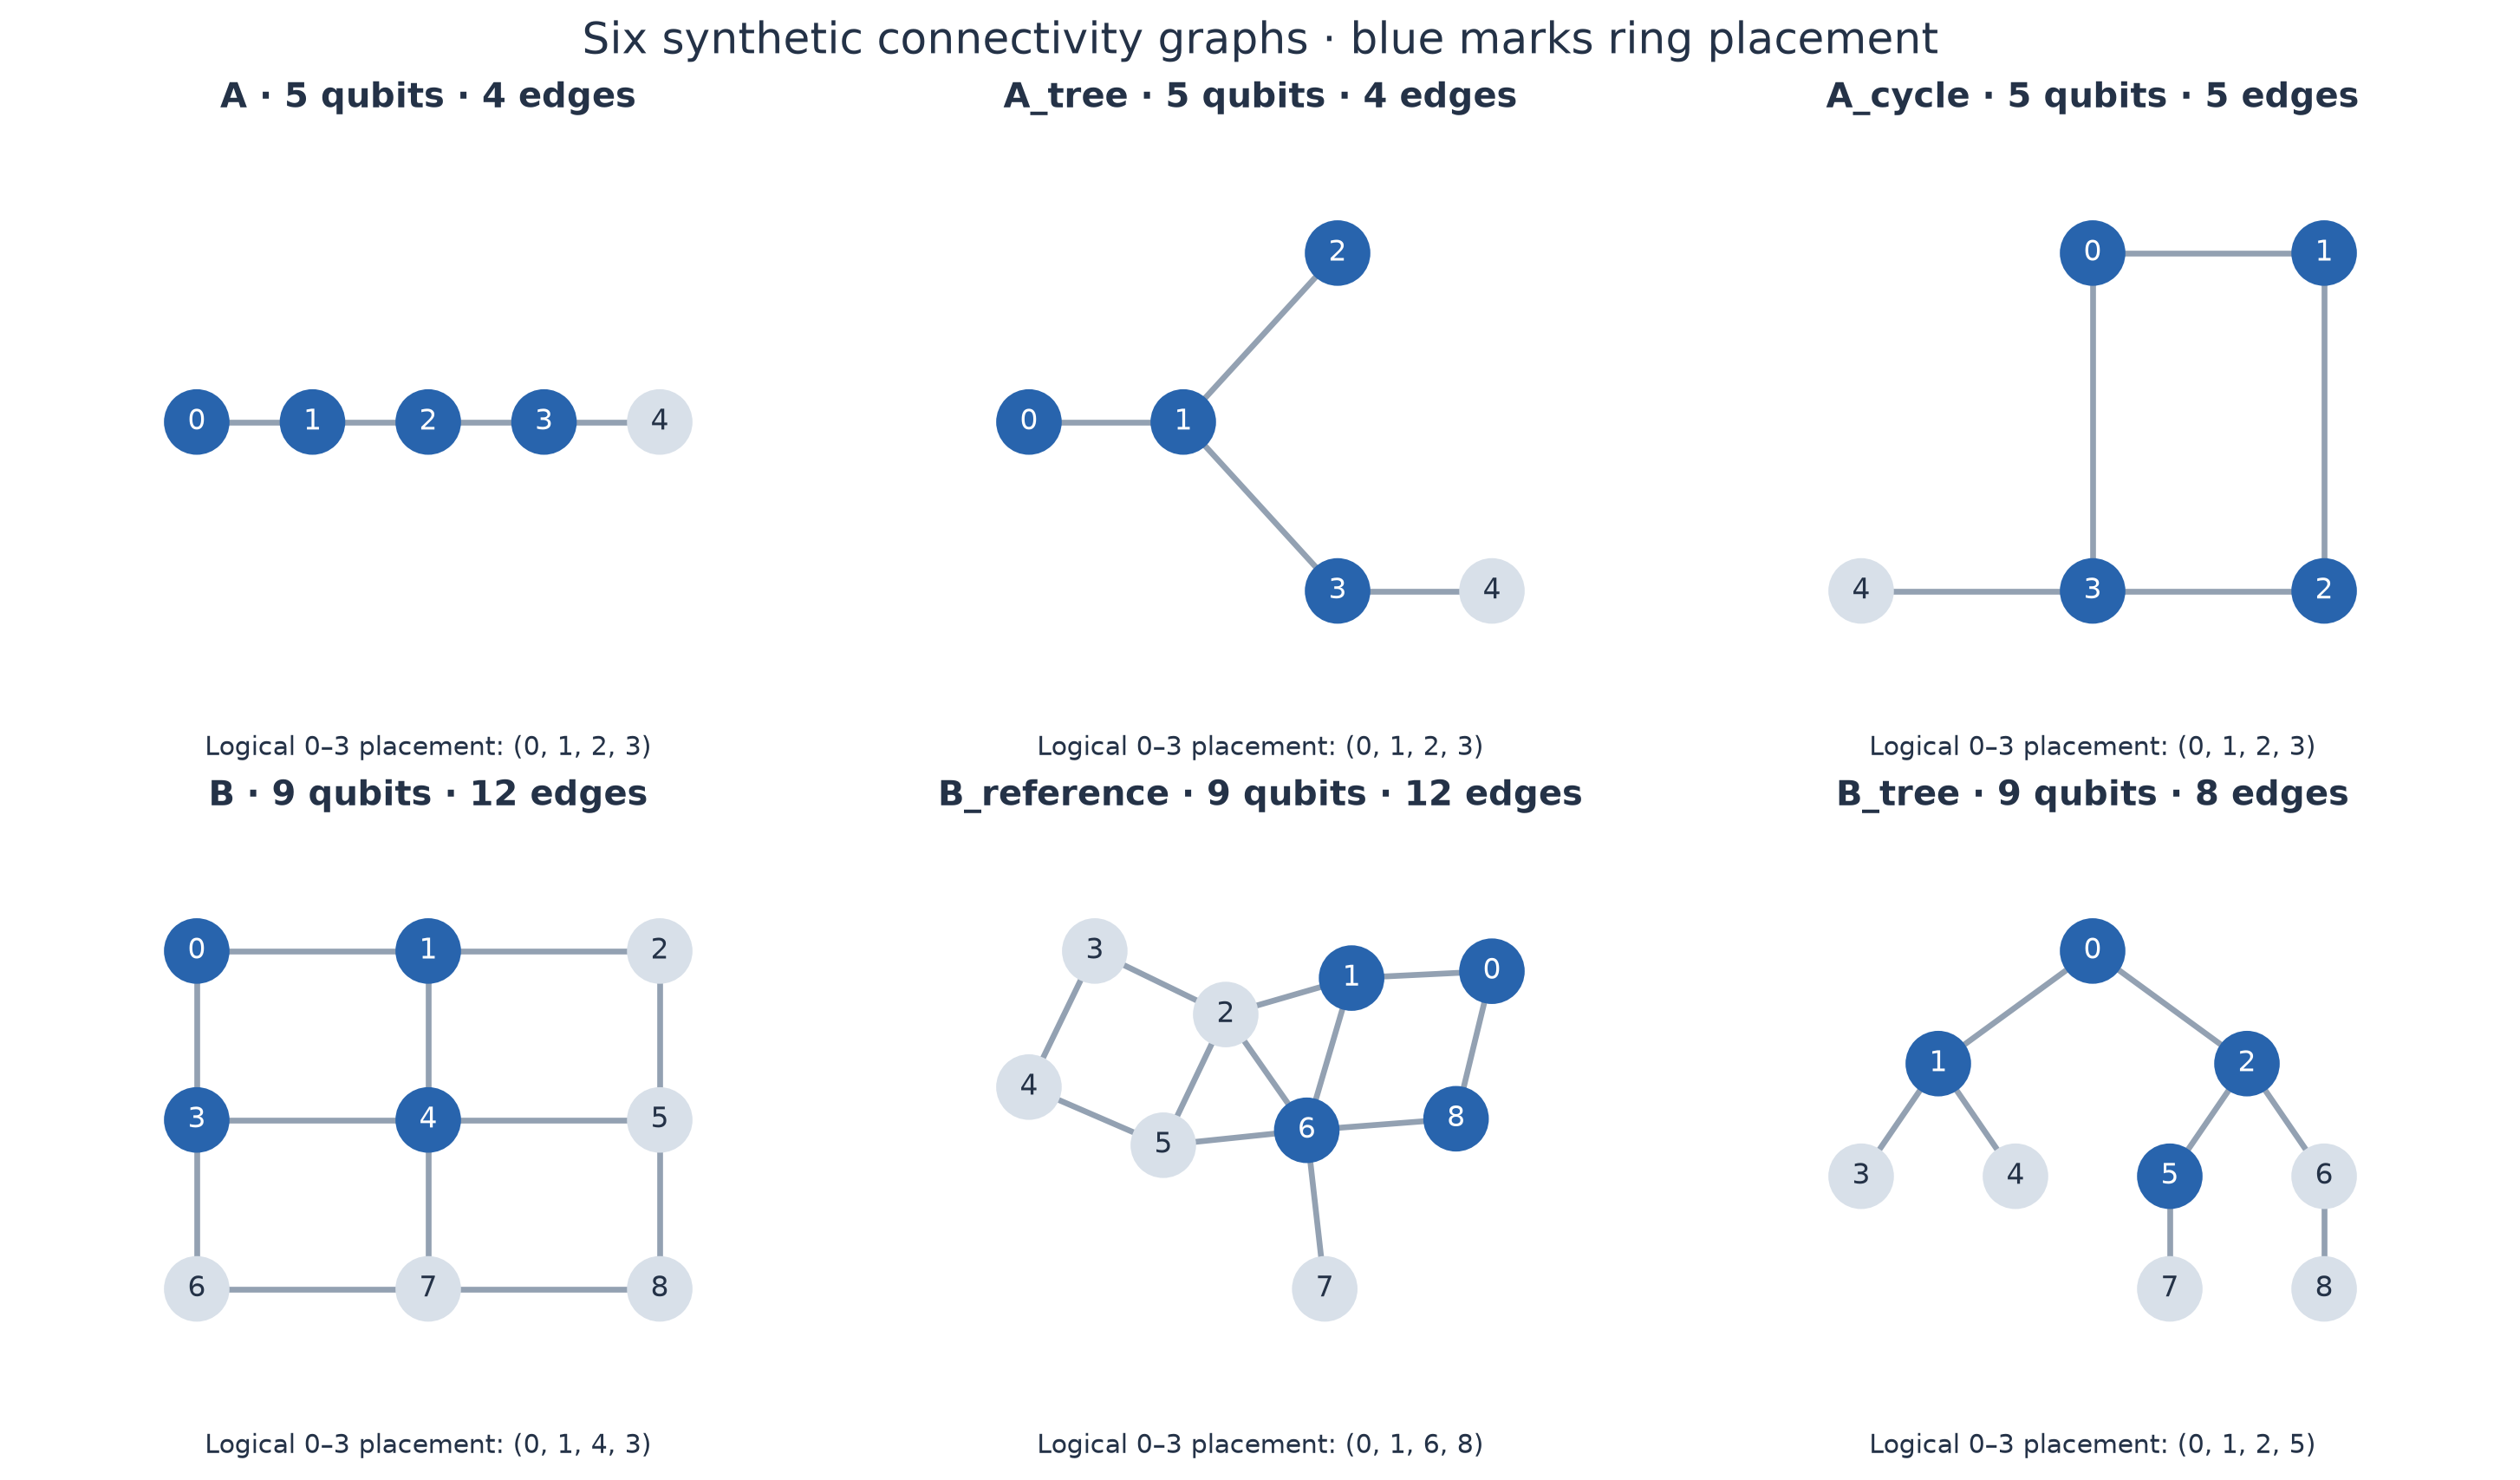

,processor,compiler,accuracy_mean,accuracy_std,accuracy_min,accuracy_max,kernel_rmse_mean,cx_mean,depth_mean,splits
0,A,baseline,0.97,0.027386,0.95,1.0,0.105269,46.8,69.0,5
1,A,fused_parity,0.99,0.022361,0.95,1.0,0.068920,22.0,39.2,5
2,B,baseline,0.96,0.065192,0.85,1.0,0.071653,23.6,50.2,5
3,B,fused_parity,0.96,0.065192,0.85,1.0,0.060377,17.6,39.2,5


,processor,split_seed,accuracy_difference,kernel_rmse_reduction,cx_reduction,cx_reduction_percent
0,A,0,0.00,0.022700,14,58.333333
1,A,1,0.05,0.052278,32,51.612903
2,A,2,0.00,0.031253,32,51.612903
3,A,3,0.00,0.022666,14,58.333333
4,A,4,0.05,0.052849,32,51.612903
5,B,0,-0.05,0.011211,6,42.857143
6,B,1,0.05,0.013149,6,20.000000
7,B,2,0.00,0.007470,6,20.000000
8,B,3,0.00,0.011304,6,42.857143
9,B,4,0.00,0.013251,6,20.000000


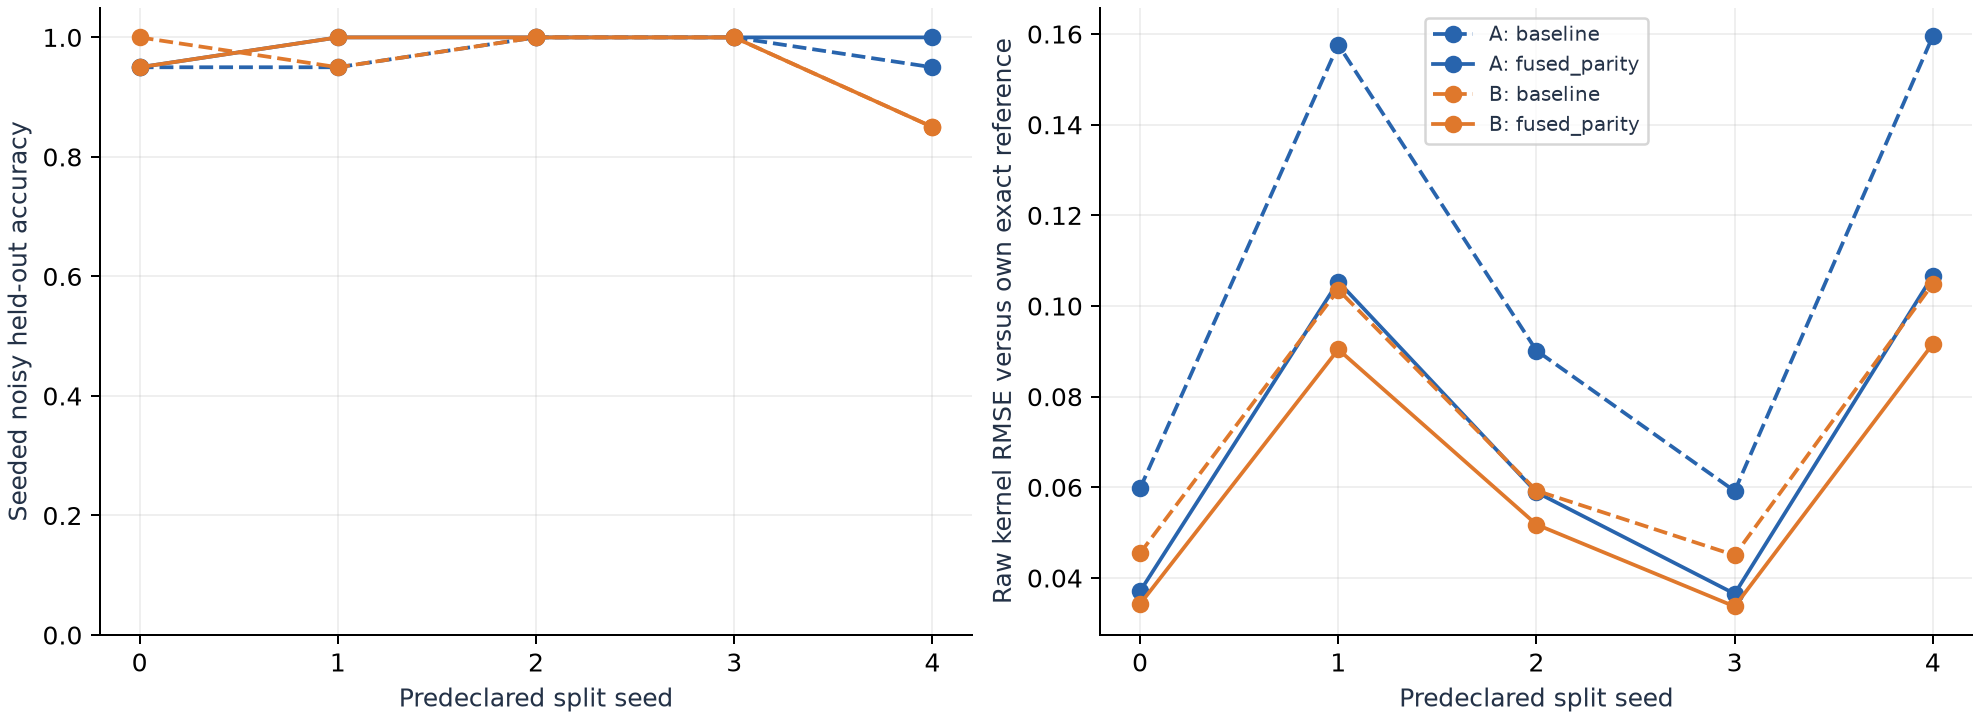

In [7]:
display(pd.read_csv(ROOT / 'results/tables/compiler_and_topology_measurements.csv')[[
    'processor','compiler','depth','cx_count','routing_swaps','kernel_rmse','accuracy','aer_seconds']])
display(pd.read_csv(ROOT / 'results/tables/compiler_resampling_summary.csv'))
display(Image(filename=str(ROOT / 'results/figures/topology_grid.png')))
display(Image(filename=str(ROOT / 'results/figures/compiler_optimization.png')))
display(pd.read_csv(ROOT / 'results/tables/encoding_training_control.csv'))
display(Image(filename=str(ROOT / 'results/figures/training_cost_quality.png')))
display(pd.read_csv(ROOT / 'results/tables/cost_aware_measurements.csv'))
display(pd.read_csv(ROOT / 'results/tables/cost_aware_resampling_summary.csv'))
robustness = pd.read_csv(ROOT / 'results/tables/nested_split_robustness.csv')
display(robustness.groupby('model').accuracy.agg(['mean','std','min','max']))
display(Image(filename=str(ROOT / 'results/figures/topology_atlas.png')))
display(pd.read_csv(ROOT / 'results/tables/noisy_split_robustness_summary.csv'))
display(pd.read_csv(ROOT / 'results/tables/noisy_split_paired_differences.csv'))
display(Image(filename=str(ROOT / 'results/figures/noisy_split_robustness.png')))


## 8. Verify the generated evidence

Tests check the overlap identity on mapped physical circuits, allowed couplings, PSD feature extension, readout inversion, shot scheduling, and saved-count reproduction of reported predictions. Artifact checksums catch stale results after code changes. Versions and settings are exported in `results/manifest.json`.


In [8]:
import subprocess
check = subprocess.run([sys.executable, '-m', 'pytest', '-q'], cwd=ROOT,
                       capture_output=True, text=True)
print(check.stdout)
if check.returncode:
    print(check.stderr)
assert check.returncode == 0, 'Scientific or artifact verification failed'
display(pd.Series(manifest['versions'], name='Installed version'))


..................                                                       [100%]
18 passed in 6.09s



qiskit           2.5.2
qiskit-aer      0.17.2
numpy            2.5.4
scipy           1.18.1
scikit-learn     1.9.1
matplotlib      3.11.2
networkx           3.7
pandas           3.0.6
Name: Installed version, dtype: str

## Interpretation and limits

Evaluate the architecture claim using CX, depth, routing SWAPs, and kernel distortion together. Better connectivity can reduce gate cost even when test accuracy is unchanged. The results concern these disclosed synthetic topologies, encoding, noise channels, and execution policy.

Four qubits are easy to simulate; this experiment establishes neither quantum speedup nor superiority over a strong classical classifier. The single small holdout limits accuracy claims. Readout mitigation assumes exact synthetic-channel knowledge. Simulator timing does not estimate hardware timing, and no physical gate durations or T1/T2 noise are supplied.

See [report.md](report.md), [README.md](README.md), and [docs/SUBMISSION_CHECKLIST.md](docs/SUBMISSION_CHECKLIST.md). Phase 1 requires only A and B.
